# O percurso do analista: notas do ENEM 2023, da base bruta ao relatório

**Curso:** Métodos Quantitativos / Tópicos de Análise Quantitativa (CAEO/CAO — CBMDF)
**Autor:** André T. Campos
**Slides de referência:** [Análise Quantitativa CAEO-2026, v11 (PDF)](https://github.com/atc857/metodos_quanti/blob/main/slides/Analise_Quantitativa_CAEO-2026_v11.pdf)

Este notebook é um **estudo de caso**. Um analista recebe uma pergunta da diretoria e a responde com os microdados do ENEM 2023, do começo ao fim: escreve o plano, confere a base, explora, limpa, descreve, lê probabilidades, trabalha com amostras, testa, modela e escreve o relatório. Os exemplos são os mesmos dos slides.

Em cada etapa aparecem três coisas:
1. **Texto** explicando a ideia, em linguagem simples;
2. o **prompt** que um analista daria a uma IA para obter o código daquela etapa, com a **verificação independente** que ele faz depois;
3. o **código** que responde ao prompt, comentado linha a linha onde é menos óbvio.

| Etapa | O que o analista faz | Slides v11 |
|---|---|---|
| 0 | Recebe a demanda e escreve o plano **antes** de abrir os dados | 2–10 |
| 1 | Obtém a base e confere se ela é a que deveria ser | 7, 11, 24–25 |
| 2 | Explora: o que há na base, o que falta e o que é estranho | 13–21 |
| 3 | Limpa: monta a base de análise com regras escritas | 19 |
| 4 | Descreve: quanto as notas variam com renda, escola, território, sexo e cor/raça | 22–45 |
| 5 | Lê probabilidades sem inverter a condicional | 47–59 |
| 6 | Trabalha com amostras: erro, intervalo, tamanho e vieses | 61–74 |
| 7 | Testa as diferenças e verifica se elas importam | 75–105 |
| 8 | Mede correlações e modela o que permanece com os outros fatores controlados | 107–125 |
| 9 | Escreve o relatório | 105, 127 |

**Como usar no Google Colab:** abra o notebook, clique em *Ambiente de execução → Executar tudo* e acompanhe de cima para baixo. As células dependem das anteriores. A base (55 MB) é baixada na Etapa 1; a execução completa leva poucos minutos.

**Fonte dos dados:** INEP, Microdados do ENEM 2023 — <https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/microdados/enem>. Cor/raça é **autodeclarada**; os recortes por cor/raça são nacionais ou de grandes grupos.

---
# Etapa 0 — A demanda e o plano de análise

**A demanda** (cenário do estudo de caso): *"Quanto o desempenho no ENEM 2023 varia com a renda da família, o tipo de escola, o território, o sexo e a cor/raça? Essas diferenças são grandes o bastante para orientar política? Quem não está nessa medição?"*

É o **fio condutor** do curso. Antes de abrir os dados, o analista escreve o que vai medir, como, e **a partir de que tamanho uma diferença importa**. Fixar esse critério antes impede que o resultado escolha o critério depois.

| # | Pergunta | Método | Como medir o tamanho | Mínimo que importa |
|---|---|---|---|---|
| P1 | Quem fica fora da medição? | proporções de presença; qui-quadrado | V de Cramér | V = 0,1 |
| P2 | Quanto as notas variam em cada dimensão? | estatística descritiva; comparação dentro de faixas de renda | diferença de médias, d de Cohen, η² | d = 0,2 |
| P3 | Escolas públicas × privadas em Matemática (Ex. 1) | teste t de Welch numa amostra planejada | d, intervalo de confiança | d = 0,2 |
| P4 | As quatro dependências administrativas (Ex. 2) | ANOVA + Tukey | η², intervalos de Tukey | d = 0,2 |
| P5 | Escolaridade do pai × renda familiar (Ex. 3) | qui-quadrado | V de Cramér | V = 0,1 |
| P6 | Quanto de cada fator permanece com os outros controlados? | regressão linear múltipla | coeficientes com intervalo, R² | — |

**Por que amostras, se temos todos os participantes?** A base é um censo de quem fez a prova. No trabalho real, quase sempre só se tem uma amostra (pesquisa de clima, auditoria de prontuários, satisfação). Nas Etapas 6 e 7 a base faz o papel de **população**: o analista sorteia amostras, faz a inferência como faria na vida real e confere o resultado contra o valor verdadeiro, que aqui é conhecido. É um laboratório.

As decisões do plano viram constantes no código: se alguém quiser mudar um critério, muda aqui, à vista.

In [1]:
# Decisões fixadas ANTES de ver os dados (o "pré-registro" do plano)
ALFA = 0.05          # nível de significância dos testes (bilaterais)
PODER = 0.80         # chance desejada de detectar o menor efeito relevante, se ele existir
D_MIN = 0.2          # menor diferença de médias que importa, em desvios padrão (d de Cohen)
V_MIN = 0.1          # menor associação entre duas variáveis categóricas que importa (V de Cramér)
NOTA_ALTA = 700      # o que chamamos de "nota alta" em Matemática na Etapa 5
ERRO_MAX = 5         # erro máximo aceito (em pontos) ao estimar a média de MT por amostra
SEMENTE = 2023       # semente dos sorteios: quem rodar de novo obtém as mesmas amostras

## 0.1 O protocolo de IA do curso

A IA entra em todas as etapas, sempre com as mesmas **7 regras**: (1) pergunta e hipótese antes dos dados; (2) não enviar dados sensíveis; (3) pedir **código**, não números; (4) contexto completo no prompt; (5) pedir premissas e limitações; (6) **verificar de forma independente**; (7) registrar tudo. Todo prompt deste notebook segue o molde **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**.

---
# Etapa 1 — Obter a base e conferir se é a que deveria ser

## 1.1 As ferramentas

Python trabalha com **bibliotecas**: pacotes de funções prontas. As usadas aqui já vêm instaladas no Colab.

In [2]:
import numpy as np                    # contas com vetores de números (médias, raízes, sorteios)
import pandas as pd                   # tabelas de dados (DataFrames): filtrar, agrupar, cruzar
import matplotlib as mpl              # gráficos (configurações gerais)
import matplotlib.pyplot as plt       # gráficos (desenho)
import seaborn as sns                 # gráficos estatísticos prontos (boxplot, mapa de calor)
from scipy import stats               # distribuições e testes estatísticos (t, qui-quadrado, ANOVA)
import statsmodels.api as sm          # regressão linear
from statsmodels.stats.power import TTestIndPower, GofChisquarePower   # tamanho de amostra pelo poder
from statsmodels.stats.multicomp import pairwise_tukeyhsd              # comparações de Tukey
from statsmodels.stats.outliers_influence import variance_inflation_factor   # diagnóstico de colinearidade
from IPython.display import display   # mostra tabelas bem formatadas no meio de uma célula
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)   # esconde avisos de versões futuras das bibliotecas
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 140)

## 1.2 Estilo dos gráficos e formato dos números

Duas convenções valem para o notebook inteiro: os gráficos têm títulos que dizem a conclusão e eixos com unidade; e os números aparecem no padrão brasileiro (1.234,5). A função `br` faz essa conversão: recebe um número e devolve o texto formatado.

In [3]:
# Paleta fixa: as mesmas cores em todos os gráficos
AZUL, LARANJA, VERDE, CINZA, VERMELHO = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984', '#e34948'
mpl.rcParams.update({
    'figure.figsize': (9, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,           # sem bordas desnecessárias
    'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False,
})

def br(x, casas=1):
    # 1234.5 -> '1.234,5': formata com vírgula decimal e ponto de milhar
    return f'{x:,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

def fmt_p(p):
    # Valor-p para relatório: abaixo de 0,001 escreve-se "< 0,001"
    return '< 0,001' if p < 0.001 else br(p, 3)

print(br(1234.567), '|', br(0.5, 2), '|', fmt_p(0.00001))

1.234,6 | 0,50 | < 0,001


## 1.3 Os rótulos do dicionário

Nos microdados, quase tudo é **código**: `TP_SEXO = 'F'`, `TP_ESCOLA = 2`, `Q006 = 'C'`. O significado de cada código está no **Dicionário de Microdados do ENEM 2023**, a planilha que o INEP publica junto com os dados. Os rótulos abaixo foram copiados dele. Cada `{ código: 'rótulo' }` é um **dicionário** do Python: uma tabela de tradução.

Regra de ouro: **nunca deduzir o significado de um código pelo nome da coluna.** `TP_ESCOLA = 1` é "Não respondeu", e não "pública".

In [4]:
ROT_SEXO = {'F': 'Feminino', 'M': 'Masculino'}
ROT_COR = {0: 'Não declarado', 1: 'Branca', 2: 'Preta', 3: 'Parda', 4: 'Amarela', 5: 'Indígena', 6: 'Não dispõe da informação'}
ROT_CONCLUSAO = {1: 'Já concluiu o EM', 2: 'Concluirá o EM em 2023', 3: 'Concluirá o EM após 2023', 4: 'Não concluiu e não está cursando'}
ROT_ESCOLA = {1: 'Não respondeu', 2: 'Pública', 3: 'Privada'}
ROT_DEPENDENCIA = {1: 'Federal', 2: 'Estadual', 3: 'Municipal', 4: 'Privada'}
ROT_PRESENCA = {0: 'Faltou', 1: 'Presente', 2: 'Eliminado'}
ROT_STATUS_RED = {1: 'Sem problemas', 2: 'Anulada', 3: 'Cópia do texto motivador', 4: 'Em branco', 6: 'Fuga ao tema',
                  7: 'Não atendimento ao tipo textual', 8: 'Texto insuficiente', 9: 'Parte desconectada'}

# Q006: renda mensal da família, em 17 faixas (A a Q); salário mínimo de 2023 = R$ 1.320
FAIXAS_RENDA = list('ABCDEFGHIJKLMNOPQ')
ROT_RENDA = {'A': 'Nenhuma renda', 'B': 'até 1.320', 'C': '1.320–1.980', 'D': '1.980–2.640', 'E': '2.640–3.300',
             'F': '3.300–3.960', 'G': '3.960–5.280', 'H': '5.280–6.600', 'I': '6.600–7.920', 'J': '7.920–9.240',
             'K': '9.240–10.560', 'L': '10.560–11.880', 'M': '11.880–13.200', 'N': '13.200–15.840',
             'O': '15.840–19.800', 'P': '19.800–26.400', 'Q': 'acima de 26.400'}
# As 17 faixas agrupadas em 4, para tabelas mais curtas
RENDA_4 = {'A': '1) até R$ 1.320', 'B': '1) até R$ 1.320',
           'C': '2) R$ 1.320–3.300', 'D': '2) R$ 1.320–3.300', 'E': '2) R$ 1.320–3.300',
           'F': '3) R$ 3.300–6.600', 'G': '3) R$ 3.300–6.600', 'H': '3) R$ 3.300–6.600'}
RENDA_4.update({letra: '4) acima de R$ 6.600' for letra in 'IJKLMNOPQ'})

# Q001: até que série o pai estudou (H = "Não sei"), agrupada em 5 níveis
INSTR_5 = {'A': '1) Fund. incompleto', 'B': '1) Fund. incompleto', 'C': '1) Fund. incompleto',
           'D': '2) Fund. completo', 'E': '3) Médio completo', 'F': '4) Superior completo', 'G': '5) Pós-graduação'}

# Território: a UF do local de prova, agrupada nas 5 regiões do IBGE
REGIAO = {'AC': 'Norte', 'AL': 'Nordeste', 'AP': 'Norte', 'AM': 'Norte', 'BA': 'Nordeste', 'CE': 'Nordeste',
          'DF': 'Centro-Oeste', 'ES': 'Sudeste', 'GO': 'Centro-Oeste', 'MA': 'Nordeste', 'MT': 'Centro-Oeste',
          'MS': 'Centro-Oeste', 'MG': 'Sudeste', 'PA': 'Norte', 'PB': 'Nordeste', 'PR': 'Sul', 'PE': 'Nordeste',
          'PI': 'Nordeste', 'RJ': 'Sudeste', 'RN': 'Nordeste', 'RS': 'Sul', 'RO': 'Norte', 'RR': 'Norte',
          'SC': 'Sul', 'SP': 'Sudeste', 'SE': 'Nordeste', 'TO': 'Norte'}
REGIOES = ['Norte', 'Nordeste', 'Centro-Oeste', 'Sudeste', 'Sul']

# Nomes das provas
AREAS = ['CN', 'CH', 'LC', 'MT']
NOTAS = ['NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'NU_NOTA_REDACAO']
NOME_NOTA = {'NU_NOTA_CN': 'Ciências da Natureza', 'NU_NOTA_CH': 'Ciências Humanas', 'NU_NOTA_LC': 'Linguagens',
             'NU_NOTA_MT': 'Matemática', 'NU_NOTA_REDACAO': 'Redação'}

## 1.4 A base

O arquivo original do INEP tem 1,7 GB e 76 colunas: grande demais para o Colab gratuito. Para o curso, ele foi reduzido às **25 colunas** usadas nas aulas, mantendo **todos os 3.933.955 inscritos** (inclusive quem faltou, porque quem falta é parte da história) e sem o número de inscrição. O resultado, em formato Parquet (colunar e comprimido), tem 55 MB e fica publicado junto com o repositório do curso.

O prompt abaixo é o que levou a essa redução (slide 11). O código que ele produz não é executado aqui, porque precisa do arquivo de 1,7 GB.

### Prompt para a IA — a redução da base

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um engenheiro de dados que escreve código reprodutível.

Contexto: Microdados do ENEM 2023 (INEP): CSV de 1,7 GB, separador ";", latin-1, 76 colunas, uma linha por inscrito; 8 colunas (TX_RESPOSTAS_* e TX_GABARITO_*) guardam respostas e gabaritos. A base vai para alunos no Colab.

Pergunta: Como gerar uma base pequena, que caiba no Colab, sem perder nenhum inscrito e com só as colunas que a aula usa?

Tarefa: (1) Converta o CSV em Parquet com DuckDB, sem carregar o arquivo no pandas, sem as colunas TX_RESPOSTAS_* e TX_GABARITO_*, com compressão zstd. (2) Desse Parquet, grave outro só com as 25 colunas da lista abaixo. (3) Imprima o número de linhas, o de colunas e o tamanho do arquivo em MB. [colar a lista de colunas]

Restrições: Não filtre nenhuma linha: os faltosos ficam. Não renomeie nem recodifique colunas. NU_INSCRICAO não entra. Os caminhos vêm de variáveis de ambiente, não escritos no código. Não envio dados, só os nomes das colunas.

Formato: Dois scripts curtos e comentados em português; depois, uma lista do que eu devo conferir para saber que a conversão não perdeu nada.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- O número de linhas da base reduzida é igual ao do CSV oficial (3.933.955)? (seção 1.5)
- São exatamente as 25 colunas pedidas, e NU_INSCRICAO não está entre elas? (seção 1.5)
- O CSV foi lido com `encoding=latin-1` e `delim=";"`? Sem isso, acentos e colunas saem errados.
- Os nulos das notas continuam nulos (não viraram zero)? (seção 2.2)

*Slides v11: 11.*

O comando `pd.read_parquet` baixa a base e a carrega numa tabela (um **DataFrame**) chamada `insc`: uma linha por **inscrito**. Ela fica intacta até o fim; as análises de desempenho usarão um recorte dela (Etapa 3).

In [5]:
URL_BASE = 'https://github.com/atc857/metodos_quanti/releases/download/base-v1/enem2023_aula.parquet'
insc = pd.read_parquet(URL_BASE)          # baixa (55 MB) e lê a base
print(f'{br(len(insc), 0)} linhas × {insc.shape[1]} colunas')
insc.head()                               # as 5 primeiras linhas, para ver a cara dos dados

3.933.955 linhas × 25 colunas


,TP_FAIXA_ETARIA,TP_SEXO,TP_COR_RACA,TP_ST_CONCLUSAO,TP_ESCOLA,IN_TREINEIRO,SG_UF_ESC,TP_DEPENDENCIA_ADM_ESC,CO_MUNICIPIO_PROVA,NO_MUNICIPIO_PROVA,SG_UF_PROVA,TP_PRESENCA_CN,TP_PRESENCA_CH,TP_PRESENCA_LC,TP_PRESENCA_MT,NU_NOTA_CN,NU_NOTA_CH,NU_NOTA_LC,NU_NOTA_MT,TP_STATUS_REDACAO,NU_NOTA_REDACAO,Q001,Q002,Q005,Q006
0,14,M,1,1,1,0,NaN,NaN,5300108,Brasília,DF,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,A,F,5,F
1,12,M,1,1,1,0,NaN,NaN,5300108,Brasília,DF,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,F,E,3,H
2,6,F,1,1,1,0,NaN,NaN,4305108,Caxias do Sul,RS,1,1,1,1,502.0,498.9,475.6,363.2,1.0,700.0,H,E,5,C
3,2,F,3,2,2,0,CE,2.0,2304400,Fortaleza,CE,1,1,1,1,459.0,508.5,507.2,466.7,1.0,880.0,D,D,5,C
4,3,F,3,2,2,0,CE,2.0,2311306,Quixadá,CE,1,1,1,1,402.5,379.2,446.9,338.3,1.0,560.0,B,B,4,B


## 1.5 A base é a que deveria ser?

Antes de qualquer análise, o analista confere a base contra o que a fonte oficial promete. Cada linha abaixo deve dar `True`.

In [6]:
COLUNAS_ESPERADAS = ['TP_FAIXA_ETARIA', 'TP_SEXO', 'TP_COR_RACA', 'TP_ST_CONCLUSAO', 'TP_ESCOLA', 'IN_TREINEIRO',
                     'SG_UF_ESC', 'TP_DEPENDENCIA_ADM_ESC', 'CO_MUNICIPIO_PROVA', 'NO_MUNICIPIO_PROVA', 'SG_UF_PROVA',
                     'TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT',
                     'NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'TP_STATUS_REDACAO', 'NU_NOTA_REDACAO',
                     'Q001', 'Q002', 'Q005', 'Q006']
print('3.933.955 linhas, como no arquivo do INEP?     ', len(insc) == 3_933_955)
print('As 25 colunas esperadas, na ordem?             ', list(insc.columns) == COLUNAS_ESPERADAS)
print('Sem o número de inscrição (NU_INSCRICAO)?      ', 'NU_INSCRICAO' not in insc.columns)
print('Q006 só com as letras A a Q?                   ', set(insc.Q006.unique()) <= set(FAIXAS_RENDA))
print('As 27 UFs de prova, todas conhecidas?          ', set(insc.SG_UF_PROVA.unique()) == set(REGIAO))
print('Notas preenchidas entre 0 e 1.000?             ', bool(((insc[NOTAS] >= 0) & (insc[NOTAS] <= 1000) | insc[NOTAS].isna()).all().all()))

3.933.955 linhas, como no arquivo do INEP?      True
As 25 colunas esperadas, na ordem?              True
Sem o número de inscrição (NU_INSCRICAO)?       True
Q006 só com as letras A a Q?                    True
As 27 UFs de prova, todas conhecidas?           True


Notas preenchidas entre 0 e 1.000?              True


## 1.6 Que tipo de variável é cada coluna, e para que ela serve aqui

O tipo da variável decide o que se pode calcular com ela (slides 24–25). E o **papel** de cada coluna na análise é decidido agora, não depois de ver os resultados.

| Coluna | Descrição (dicionário do INEP) | Tipo | Papel na análise |
|---|---|---|---|
| `NU_NOTA_CN`, `_CH`, `_LC`, `_MT`, `_REDACAO` | Nota da prova (0 a 1.000) | quantitativa contínua | **desfecho**: o que se quer explicar |
| `TP_PRESENCA_CN`, `_CH`, `_LC`, `_MT` | Presença na prova objetiva (0 faltou, 1 presente, 2 eliminado) | qualitativa nominal | filtro; quem fica fora (P1) |
| `TP_STATUS_REDACAO` | Situação da redação (1 = sem problemas) | qualitativa nominal | filtro |
| `Q006` | Renda mensal da família (17 faixas, A a Q) | qualitativa **ordinal** | dimensão: **renda** |
| `TP_ESCOLA` | Tipo de escola do ensino médio | qualitativa nominal | dimensão: **escola** (P3) |
| `TP_DEPENDENCIA_ADM_ESC` | Dependência administrativa da escola | qualitativa nominal | dimensão: **escola** (P4) |
| `SG_UF_PROVA` | UF do local de prova | qualitativa nominal | dimensão: **território** |
| `TP_SEXO` | Sexo | qualitativa nominal | dimensão: **sexo** |
| `TP_COR_RACA` | Cor/raça (autodeclarada) | qualitativa nominal | dimensão: **cor/raça** |
| `Q001` | Até que série o pai (ou responsável) estudou | qualitativa ordinal | P5, com a renda |
| `TP_ST_CONCLUSAO` | Situação de conclusão do ensino médio | qualitativa nominal | explica quem informa a escola |
| `TP_FAIXA_ETARIA`, `IN_TREINEIRO` | Faixa etária; inscrito só para treinar | ordinal; nominal | cuidado com a composição (6.8) |
| `Q005` | Nº de moradores da residência | quantitativa discreta | não usada |
| `SG_UF_ESC`, `CO_`/`NO_MUNICIPIO_PROVA`, `Q002` | UF da escola; município da prova; escolaridade da mãe | — | não usadas (município: risco de reidentificar pessoas) |

**Alerta:** `Q006` é uma **faixa**, não um valor em reais. "Média de renda" calculada com os códigos A a Q é erro.

---
# Etapa 2 — Análise exploratória: o que há na base, o que falta e o que é estranho

> *"Antes de testar qualquer hipótese, conheça seus dados: de onde vêm, o que significa cada coluna, o que falta e o que é estranho."*

Roteiro de perfilamento (slide 15): **origem → estrutura → ausentes → códigos → variáveis numéricas → relações**. Nada é apagado nesta etapa. Tudo o que for encontrado vai para o **registro de qualidade** (2.6), e a limpeza só acontece na Etapa 3, com regras escritas.

### Prompt para a IA — a análise exploratória

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um analista de qualidade de dados.

Contexto: Arquivo Parquet com os microdados do ENEM 2023 (3,9 milhões de linhas). Colo abaixo o trecho do dicionário das colunas que usarei (nome, descrição, categorias). [colar o trecho do dicionário]

Pergunta: A base está pronta para comparar notas por tipo de escola? O que falta, o que está codificado e o que é estranho?

Tarefa: Escreva um script que gere um relatório de qualidade: (1) nº de linhas; (2) % de nulos por coluna; (3) para cada NU_NOTA_*, o cruzamento do nulo com o TP_PRESENCA_* da mesma prova; (4) frequência de TP_ESCOLA e de TP_DEPENDENCIA_ADM_ESC, com os rótulos do dicionário; (5) número de notas iguais a zero e de notas máximas.

Restrições: Use só colunas do dicionário que enviei; se precisar de outra, pergunte antes. Não interprete nem tire conclusões. Nenhum dado real vai no prompt: só a estrutura.

Formato: Um bloco de código comentado por item e, ao final, uma tabela dizendo o que cada bloco produz.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- Linhas = 3.933.955 (CSV oficial).
- Nulo da nota = ausência na prova, em todas as linhas (seção 2.2).
- Rótulos vêm do dicionário, não da "memória" do modelo.
- TP_ESCOLA = 1 é "Não respondeu", não "pública" (seção 2.3).
- Toda causa proposta pela IA é hipótese: confira na documentação do INEP.

*Slides v11: 21.*

## 2.1 Estrutura e ausências: quanto falta em cada coluna?

`insc.isna()` marca cada célula vazia com `True`; `.mean()` dá a fração de `True` em cada coluna. Multiplicando por 100, temos o % de vazios.

In [7]:
pct_vazios = (insc.isna().mean() * 100).round(1)           # % de células vazias em cada coluna
distintos = insc.nunique()                                  # quantos valores diferentes cada coluna tem
estrutura = pd.DataFrame({'tipo': insc.dtypes.astype(str), '% vazios': pct_vazios, 'valores distintos': distintos})
estrutura

,tipo,% vazios,valores distintos
TP_FAIXA_ETARIA,int64,0.0,20
TP_SEXO,str,0.0,2
TP_COR_RACA,int64,0.0,6
TP_ST_CONCLUSAO,int64,0.0,4
TP_ESCOLA,int64,0.0,3
IN_TREINEIRO,int64,0.0,2
SG_UF_ESC,str,75.6,27
TP_DEPENDENCIA_ADM_ESC,float64,75.6,4
CO_MUNICIPIO_PROVA,int64,0.0,1750
NO_MUNICIPIO_PROVA,str,0.0,1715


Uma contagem de vazios, sozinha, não diz nada. A pergunta que importa é: **por que** está faltando? Três colunas chamam a atenção: as notas (cerca de 30% vazias) e as duas da escola (75% vazias).

## 2.2 Nota vazia = ausência na prova

Hipótese: a nota é vazia porque a pessoa não fez a prova. `pd.crosstab` cruza duas colunas e conta quantas linhas há em cada combinação.

In [8]:
nota_vazia = insc.NU_NOTA_MT.isna().map({True: 'nota vazia', False: 'nota preenchida'})
presenca = insc.TP_PRESENCA_MT.map(ROT_PRESENCA)
pd.crosstab(presenca, nota_vazia, margins=True, margins_name='Total')

NU_NOTA_MT,nota preenchida,nota vazia,Total
TP_PRESENCA_MT,,,
Eliminado,0,2212,2212
Faltou,0,1239316,1239316
Presente,2692427,0,2692427
Total,2692427,1241528,3933955


In [9]:
# Verificação nas quatro provas: "nota vazia" coincide com "não presente" em TODAS as linhas?
for a in AREAS:
    vazia = insc[f'NU_NOTA_{a}'].isna()              # True onde a nota está vazia
    ausente = insc[f'TP_PRESENCA_{a}'] != 1          # True onde a pessoa não estava presente
    print(f'{a}: coincidem em todas as linhas? {bool((vazia == ausente).all())} | presentes: {br((~ausente).sum(), 0)}')

CN: coincidem em todas as linhas? True | presentes: 2.692.427
CH: coincidem em todas as linhas? True | presentes: 2.822.643
LC: coincidem em todas as linhas? True | presentes: 2.822.643
MT: coincidem em todas as linhas? True | presentes: 2.692.427


**Conclusão:** o vazio **é** a ausência. Tratar nota vazia como zero criaria uma média falsa, puxada para baixo por quem nem fez a prova. Regra: usar só os presentes.

## 2.3 A armadilha da escola

Quem responde ao tipo de escola? Cruzando com a situação de conclusão do ensino médio:

In [10]:
pd.crosstab(insc.TP_ST_CONCLUSAO.map(ROT_CONCLUSAO), insc.TP_ESCOLA.map(ROT_ESCOLA), margins=True, margins_name='Total')

TP_ESCOLA,Não respondeu,Privada,Pública,Total
TP_ST_CONCLUSAO,,,,
Concluirá o EM após 2023,620067,0,0,620067
Concluirá o EM em 2023,5,234619,1166540,1401164
Já concluiu o EM,1895301,0,0,1895301
Não concluiu e não está cursando,17423,0,0,17423
Total,2532796,234619,1166540,3933955


Só quem **concluirá o ensino médio em 2023** informa a escola. Quem já concluiu, os treineiros e quem não estuda aparecem como "Não respondeu". E a dependência administrativa (federal, estadual, municipal, privada) falta até para parte desses concluintes:

In [11]:
conc23 = insc[insc.TP_ST_CONCLUSAO == 2]                  # só os concluintes de 2023
sem_dep = conc23.TP_DEPENDENCIA_ADM_ESC.isna()            # True onde a dependência está vazia
print(f'Concluintes de 2023: {br(len(conc23), 0)}; sem dependência administrativa: {br(sem_dep.sum(), 0)} ({br(100 * sem_dep.mean())}%)')
print(f'  entre os de escola pública: {br(100 * sem_dep[conc23.TP_ESCOLA == 2].mean())}% sem dependência')
print(f'  entre os de escola privada: {br(100 * sem_dep[conc23.TP_ESCOLA == 3].mean())}% sem dependência')

Concluintes de 2023: 1.401.164; sem dependência administrativa: 442.658 (31,6%)
  entre os de escola pública: 35,4% sem dependência
  entre os de escola privada: 12,5% sem dependência


**Conclusão:** "pública × privada" compara **concluintes de 2023**, não "os candidatos do ENEM". E "federal × estadual × municipal × privada" é um subconjunto **não aleatório**: a dependência falta mais para quem declarou escola pública.

## 2.4 Zeros que não medem desempenho

O zero é uma nota muito baixa ou um registro administrativo? Antes de apagar, investigar.

In [12]:
zeros = {}
for n in NOTAS:
    x = insc[n].dropna()                                   # só as notas preenchidas
    zeros[NOME_NOTA[n]] = {'zeros': (x == 0).sum(), 'menor nota acima de zero': x[x > 0].min(), 'nota máxima': x.max()}
pd.DataFrame(zeros).T

,zeros,menor nota acima de zero,nota máxima
Ciências da Natureza,16547.0,316.1,868.4
Ciências Humanas,5612.0,289.9,823.0
Linguagens,2169.0,287.0,820.8
Matemática,16638.0,319.8,958.6
Redação,117829.0,40.0,1000.0


In [13]:
# Redação: em que situação estão as redações com nota zero?
zero_red = insc.NU_NOTA_REDACAO == 0
display(insc.loc[zero_red, 'TP_STATUS_REDACAO'].map(ROT_STATUS_RED).value_counts().to_frame('redações com nota 0'))
print('Alguma redação com nota 0 está "Sem problemas"?', bool((insc.loc[zero_red, 'TP_STATUS_REDACAO'] == 1).any()))
print('Todas as notas de redação são múltiplos de 20?  ', bool((insc.NU_NOTA_REDACAO.dropna() % 20 == 0).all()))

,redações com nota 0
TP_STATUS_REDACAO,
Em branco,55403
Fuga ao tema,24466
Cópia do texto motivador,22505
Texto insuficiente,9091
Parte desconectada,2443
Anulada,2016
Não atendimento ao tipo textual,1905


Alguma redação com nota 0 está "Sem problemas"? False
Todas as notas de redação são múltiplos de 20?   True


**O que os zeros são:**
- **Redação:** todo zero vem de uma redação com problema (em branco, fuga ao tema, cópia do texto motivador...). É um **zero administrativo**.
- **Provas objetivas:** não existe nota entre 0 e ≈ 290; o zero é um salto. Consultando o arquivo completo do INEP (que traz as respostas marcadas e não está nesta base), **todos os zeros das objetivas são cartões sem nenhuma resposta marcada**.

Nos dois casos, o zero não mede desempenho. Excluir esses casos é uma decisão justificada; apagar "toda linha com algum zero" sem saber por quê, não.

## 2.5 A forma das notas

Um **histograma** divide a escala em intervalos e conta quantas pessoas caem em cada um.

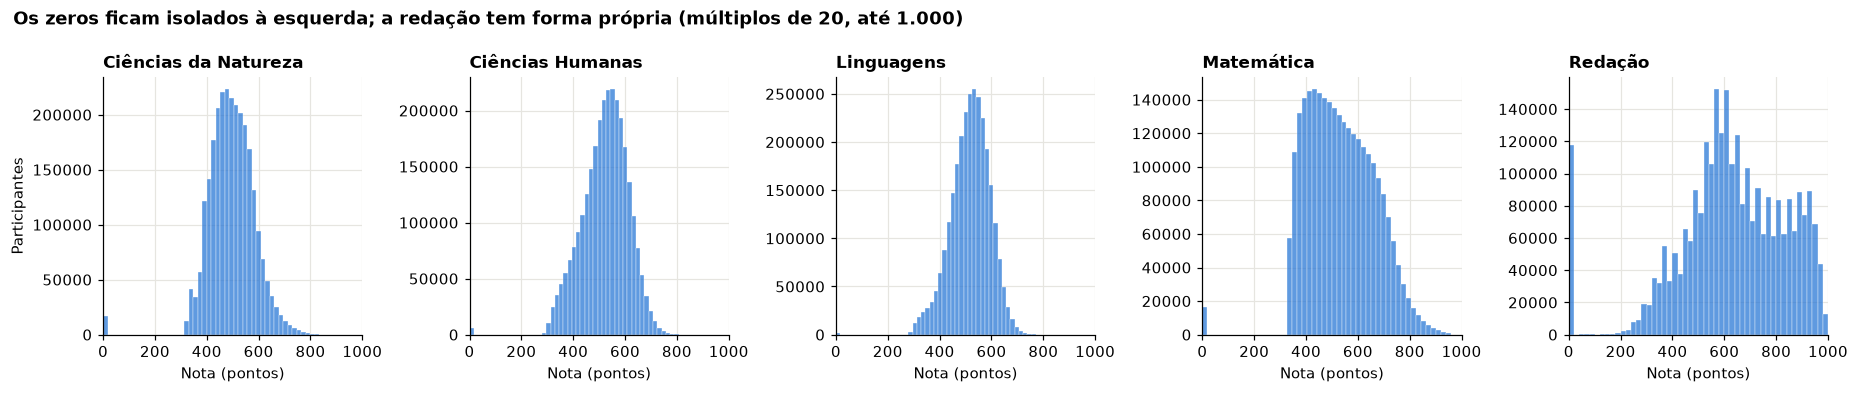

In [14]:
fig, eixos = plt.subplots(1, 5, figsize=(17, 3.6))          # 5 gráficos lado a lado
for ax, n in zip(eixos, NOTAS):
    ax.hist(insc[n].dropna(), bins=50, color=AZUL, alpha=0.75, edgecolor='white', linewidth=0.3)
    ax.set_title(NOME_NOTA[n], fontsize=11)
    ax.set_xlabel('Nota (pontos)')
    ax.set_xlim(0, 1000)
eixos[0].set_ylabel('Participantes')
fig.suptitle('Os zeros ficam isolados à esquerda; a redação tem forma própria (múltiplos de 20, até 1.000)',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

## 2.6 Registro de qualidade

Tudo o que a exploração encontrou, com a evidência e a decisão que será aplicada na Etapa 3. Este registro vai para o anexo do relatório.

| Problema | Evidência (seções 2.1 a 2.4) | Decisão |
|---|---|---|
| Nota vazia | as 1.241.528 notas de MT vazias são todas de não presentes | usar só presentes; nunca tratar vazio como zero |
| `TP_ESCOLA` restrita | 64,4% "Não respondeu"; só concluintes de 2023 respondem | comparar escolas só entre concluintes de 2023 e dizer isso no relatório |
| Dependência administrativa incompleta | falta para 35,4% dos concluintes de escola pública e 12,5% dos de privada | o Ex. 2 é um subconjunto não aleatório: declarar como limitação |
| Zero na redação | 117.829 zeros, todos de redações com problema | manter só redações "sem problemas" |
| Zero nas objetivas | 40.966 zeros; nenhuma nota entre 0 e ≈ 290 | excluir quem teve alguma objetiva com 0 (cartão em branco) |
| Quem falta é aleatório? | a verificar (seção 6.7) | analisar a presença com **todos** os inscritos |

## 2.7 Bases grandes: como ler e guardar

A base ocupa cerca de 850 MB na memória, embora o arquivo tenha 55 MB. Três hábitos ajudam (slide 20): ler **só as colunas necessárias**, usar formatos colunares como o **Parquet** e guardar colunas de texto repetitivo (UF, letras do questionário) como `category`, que armazena cada valor diferente uma vez só.

In [15]:
mem = insc.memory_usage(deep=True).sum() / 1e6              # memória ocupada, em MB
texto = insc.select_dtypes(exclude='number').columns          # colunas de texto
mem_cat = insc.astype({c: 'category' for c in texto}).memory_usage(deep=True).sum() / 1e6
print(f'Na memória: {br(mem, 0)} MB | com as {len(texto)} colunas de texto como category: {br(mem_cat, 0)} MB')
print('Para ler só algumas colunas: pd.read_parquet(URL_BASE, columns=["NU_NOTA_MT", "TP_ESCOLA"])')

Na memória: 854 MB | com as 7 colunas de texto como category: 598 MB
Para ler só algumas colunas: pd.read_parquet(URL_BASE, columns=["NU_NOTA_MT", "TP_ESCOLA"])


---
# Etapa 3 — Limpeza: a base de análise, com as regras registradas

Com o perfil feito, a decisão de quem entra na análise de desempenho vira um prompt, e o prompt vira código.

### Prompt para a IA — a limpeza

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um analista de dados que documenta cada decisão de limpeza.

Contexto: DataFrame insc com todos os inscritos do ENEM 2023 (3.933.955 linhas). Colunas: TP_PRESENCA_CN, TP_PRESENCA_CH, TP_PRESENCA_LC, TP_PRESENCA_MT (0 faltou, 1 presente, 2 eliminado); NU_NOTA_CN, NU_NOTA_CH, NU_NOTA_LC, NU_NOTA_MT, NU_NOTA_REDACAO (vazias para ausentes); TP_STATUS_REDACAO (1 = sem problemas). O perfil mostrou: nota vazia = ausência; zero na redação = situação diferente de 1; zero nas objetivas = cartão em branco.

Pergunta: Quem deve entrar na base para comparar desempenho entre grupos?

Tarefa: (1) Aplique, nesta ordem, as regras: presente nas 4 provas objetivas; redação sem problemas; nenhuma prova objetiva com nota 0. (2) Monte um funil com o n e o % dos inscritos depois de cada regra. (3) Crie a coluna MEDIA_GERAL (média das cinco notas). (4) Confira que na base final não sobram nulos nem zeros nas notas.

Restrições: Não altere insc: as análises de presença usam todos os inscritos. Nenhuma linha sai sem regra escrita. Só código, sem números.

Formato: Código comentado; o funil em tabela; ao final, uma limitação de cada regra (quem ela tira e se esse grupo é aleatório).
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- O funil termina em 2.569.190 participantes (65,3% dos inscritos)?
- Nenhum nulo e nenhum zero nas cinco notas da base final.
- insc continua com 3.933.955 linhas.
- As limitações dizem que quem falta não é aleatório (a presença cresce com a renda; seção 6.7).

*Slides v11: 19.*

Cada regra vira uma **máscara**: uma coluna de `True`/`False`, uma por inscrito. Combinar máscaras com `&` ("e") e negar com `~` ("não") permite contar quem passa em cada regra e, no fim, filtrar.

In [16]:
# Regra 1: presente nas 4 provas objetivas (as 4 colunas de presença iguais a 1)
presente_4 = (insc[['TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT']] == 1).all(axis=1)
# Regra 2: redação sem problemas
redacao_ok = insc.TP_STATUS_REDACAO == 1
# Regra 3: nenhuma prova objetiva com nota 0 (cartão em branco)
em_branco = (insc[['NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT']] == 0).any(axis=1)

funil = pd.Series({
    'Inscritos': len(insc),
    '1) presentes nas 4 provas objetivas': presente_4.sum(),
    '2) ... e redação sem problemas': (presente_4 & redacao_ok).sum(),
    '3) ... e nenhuma objetiva em branco = BASE DE ANÁLISE': (presente_4 & redacao_ok & ~em_branco).sum(),
})
base = insc[presente_4 & redacao_ok & ~em_branco].copy()     # a base de análise (cópia; insc não muda)
pd.DataFrame({'participantes': funil, '% dos inscritos': (100 * funil / len(insc)).round(1)})

,participantes,% dos inscritos
Inscritos,3933955,100.0
1) presentes nas 4 provas objetivas,2678264,68.1
2) ... e redação sem problemas,2585115,65.7
3) ... e nenhuma objetiva em branco = BASE DE ANÁLISE,2569190,65.3


Agora, **variáveis derivadas**: colunas novas com rótulos legíveis, feitas a partir do dicionário. O método `.map(dicionário)` troca cada código pelo seu rótulo. Os códigos originais continuam na base.

In [17]:
base['renda'] = base.Q006.map({letra: i + 1 for i, letra in enumerate(FAIXAS_RENDA)})   # A=1, B=2, ..., Q=17
base['renda_4'] = base.Q006.map(RENDA_4)                     # renda em 4 faixas
base['escola'] = base.TP_ESCOLA.map(ROT_ESCOLA)
base['dependencia'] = base.TP_DEPENDENCIA_ADM_ESC.map(ROT_DEPENDENCIA)   # fica vazia para quem não a informou
base['regiao'] = base.SG_UF_PROVA.map(REGIAO)
base['sexo'] = base.TP_SEXO.map(ROT_SEXO)
base['cor'] = base.TP_COR_RACA.map(ROT_COR)

# Verificação independente da limpeza
print('Base de análise com 2.569.190 participantes?', len(base) == 2_569_190)
print('Nenhum vazio nas cinco notas?               ', int(base[NOTAS].isna().sum().sum()) == 0)
print('Nenhum zero nas cinco notas?                ', int((base[NOTAS] == 0).sum().sum()) == 0)
print('insc intacto (3.933.955 linhas)?            ', len(insc) == 3_933_955)
print('Toda UF ganhou uma região?                  ', bool(base.regiao.notna().all()))

Base de análise com 2.569.190 participantes? True
Nenhum vazio nas cinco notas?                True
Nenhum zero nas cinco notas?                 True
insc intacto (3.933.955 linhas)?             True
Toda UF ganhou uma região?                   True


*Limitação a declarar:* quem faltou a um dos dias, foi eliminado ou teve a redação anulada sai da base. Daqui em diante, **desempenho** se analisa na base de análise (`base`); **presença**, com todos os inscritos (`insc`).

---
# Etapa 4 — Descrever: quanto as notas variam em cada dimensão (P2)

> *Existe um "aluno típico" no ENEM?* Resumir é perder informação de propósito: escolha o resumo que preserva o que importa para a decisão.

Para cada dimensão do fio condutor: uma tabela com **n** (quantos), **média**, **mediana** e **dispersão**; uma medida do **tamanho** da diferença; e um gráfico honesto.

## 4.1 Matemática por tipo de escola: o resumo

### Prompt para a IA — a estatística descritiva

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um analista de dados que escreve código Python claro e auditável.

Contexto: DataFrame pandas base com a base de análise do ENEM 2023 (2.569.190 participantes presentes nas quatro provas, redação sem problemas, sem notas zero). Colunas: NU_NOTA_MT (número, 0 a 1000); TP_ESCOLA (1 não respondeu, 2 pública, 3 privada; só concluintes de 2023 respondem).

Pergunta: Como se distribui a nota de Matemática em cada tipo de escola?

Tarefa: (1) Calcule por TP_ESCOLA: n, média, mediana, desvio padrão amostral, primeiro e terceiro quartis, mínimo, máximo e assimetria. (2) Desenhe, para pública e privada, o histograma da nota com a média e a mediana marcadas.

Restrições: Declare o ddof do desvio padrão e o método dos quartis. Trate TP_ESCOLA = 1 como categoria à parte e mostre quantos casos tem. Use groupby, sem laços. Não calcule números: só o código.

Formato: Código comentado em português e, ao final, 3 decisões de tratamento que você tomou e que eu devo confirmar.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- O desvio padrão é o amostral (ddof = 1, padrão do pandas; o NumPy usa ddof = 0)?
- O método dos quartis está declarado?
- A soma dos n dá 2.569.190 (a base inteira)?
- Refazer uma linha sem `groupby` e comparar (célula seguinte).
- "Não respondeu" aparece com o seu n, e não somada à pública.

*Slides v11: 45.*

`groupby` separa a base em grupos (aqui, pelo tipo de escola) e `agg` calcula vários resumos de uma vez em cada grupo:
- **média** e **mediana** (o valor do meio): duas ideias de "centro";
- **desvio padrão (dp)**: o quanto as notas se espalham em torno da média;
- **Q1 e Q3** (quartis): 25% das notas ficam abaixo de Q1 e 25% acima de Q3;
- **assimetria**: positiva quando há cauda longa à direita (poucas notas muito altas), negativa no caso contrário.

In [18]:
resumo_escola = (base.groupby('escola').NU_NOTA_MT
                 .agg(n='count', média='mean', mediana='median',
                      dp=lambda s: s.std(ddof=1),                        # desvio padrão amostral (divide por n − 1)
                      Q1=lambda s: s.quantile(0.25), Q3=lambda s: s.quantile(0.75),   # quartis (método linear, o padrão)
                      mín='min', máx='max', assimetria='skew')
                 .loc[['Pública', 'Privada', 'Não respondeu']])
resumo_escola['% da base'] = 100 * resumo_escola.n / len(base)
resumo_escola.round(2)

,n,média,mediana,dp,Q1,Q3,mín,máx,assimetria,% da base
escola,,,,,,,,,,
Pública,783634,511.23,498.9,109.41,421.3,591.3,322.1,958.6,0.43,30.50
Privada,219207,633.03,647.9,121.30,551.0,719.4,328.2,958.6,-0.28,8.53
Não respondeu,1566349,542.36,531.1,126.16,437.4,636.9,321.3,958.6,0.37,60.97


In [19]:
# Verificação independente: a soma dos n e uma linha refeita sem groupby
print('Soma dos n = tamanho da base?', resumo_escola.n.sum() == len(base))
priv = base.loc[base.TP_ESCOLA == 3, 'NU_NOTA_MT'].to_numpy()      # notas de MT das privadas, como vetor
print(f'Privada sem groupby: média {br(priv.mean(), 2)} | dp com ddof=1: {br(priv.std(ddof=1), 4)} | com ddof=0: {br(priv.std(ddof=0), 4)}')

Soma dos n = tamanho da base? True
Privada sem groupby: média 633,03 | dp com ddof=1: 121,2985 | com ddof=0: 121,2982


## 4.2 Média ou mediana? Depende da forma

Quando a distribuição é simétrica, média e mediana quase coincidem. Quando há uma cauda, a média é puxada para o lado dela. Comparar as duas já denuncia a assimetria (slide 32).

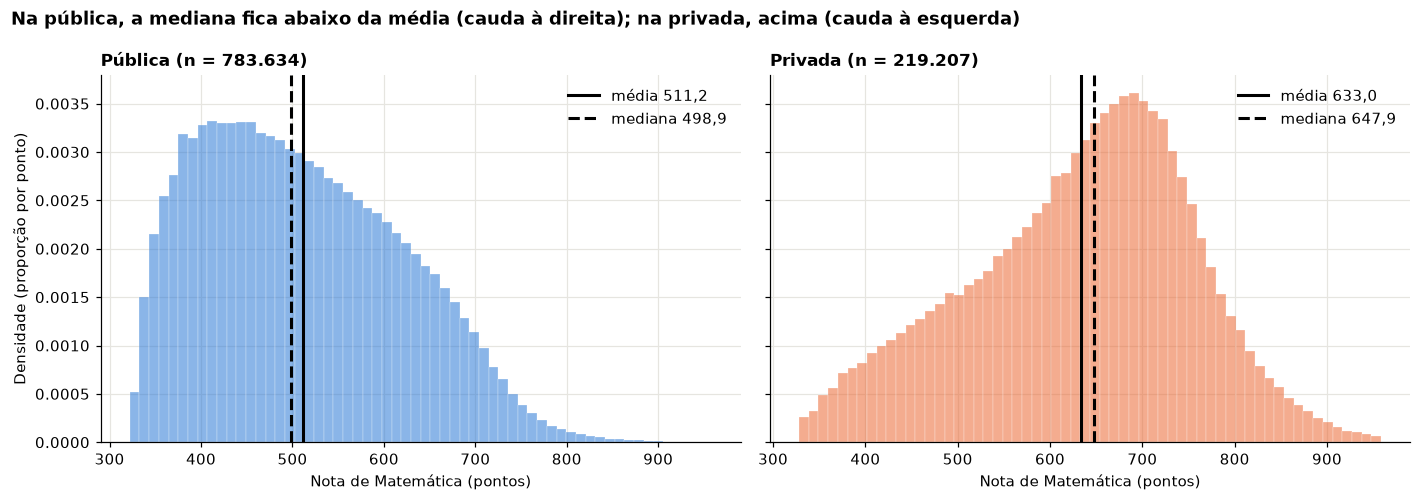

In [20]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, codigo, nome, cor in ((eixos[0], 2, 'Pública', AZUL), (eixos[1], 3, 'Privada', LARANJA)):
    x = base.loc[base.TP_ESCOLA == codigo, 'NU_NOTA_MT']
    ax.hist(x, bins=60, density=True, color=cor, alpha=0.55, edgecolor='white', linewidth=0.3)
    ax.axvline(x.mean(), color='black', lw=2, label=f'média {br(x.mean())}')              # linha cheia: média
    ax.axvline(x.median(), color='black', lw=2, ls='--', label=f'mediana {br(x.median())}')   # tracejada: mediana
    ax.set_title(f'{nome} (n = {br(len(x), 0)})', fontsize=11)
    ax.set_xlabel('Nota de Matemática (pontos)')
    ax.legend(loc='upper right')
eixos[0].set_ylabel('Densidade (proporção por ponto)')
fig.suptitle('Na pública, a mediana fica abaixo da média (cauda à direita); na privada, acima (cauda à esquerda)',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

**Leitura:** a privada tem média de MT bem maior, e a forma também muda. A categoria "Não respondeu" (61% da base) **não** é escola nenhuma: fica visível na tabela, mas não entra na comparação.

## 4.3 Renda: o gradiente

A média de MT em cada uma das 17 faixas de renda. Num gráfico de barras, **o eixo começa em zero**: o comprimento da barra é o valor.

,renda familiar (R$),n,média,mediana
Q006,,,,
A,Nenhuma renda,144154,461.6,440.5
B,até 1.320,733318,483.2,466.0
C,1.320–1.980,397170,516.4,506.4
D,1.980–2.640,285154,536.5,531.2
E,2.640–3.300,203099,554.9,553.5
F,3.300–3.960,123646,573.4,577.2
G,3.960–5.280,196822,589.0,595.7
H,5.280–6.600,108022,606.9,617.3
I,6.600–7.920,68088,617.8,630.5


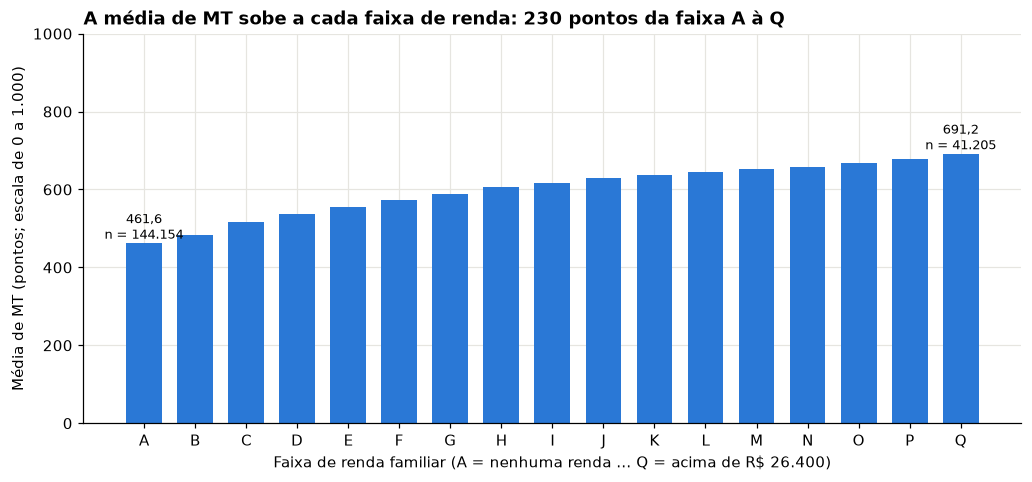

In [21]:
por_renda = base.groupby('Q006').NU_NOTA_MT.agg(n='count', média='mean', mediana='median').loc[FAIXAS_RENDA]
por_renda.insert(0, 'renda familiar (R$)', [ROT_RENDA[letra] for letra in FAIXAS_RENDA])
display(por_renda.round(1))

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.bar(por_renda.index, por_renda['média'], color=AZUL, width=0.7)
for i in (0, 16):                                              # rótulo só na primeira e na última barra
    ax.text(i, por_renda['média'].iloc[i] + 12, f"{br(por_renda['média'].iloc[i])}\nn = {br(por_renda.n.iloc[i], 0)}",
            ha='center', fontsize=8.5)
ax.set_ylim(0, 1000)
ax.set_xlabel('Faixa de renda familiar (A = nenhuma renda ... Q = acima de R$ 26.400)')
ax.set_ylabel('Média de MT (pontos; escala de 0 a 1.000)')
ax.set_title(f"A média de MT sobe a cada faixa de renda: {br(por_renda['média'].iloc[-1] - por_renda['média'].iloc[0], 0)} pontos da faixa A à Q")
plt.show()

## 4.4 Escola: as quatro dependências administrativas

Um **boxplot** resume cada grupo numa caixa: a linha do meio é a mediana, a caixa vai de Q1 a Q3 (onde estão os 50% do meio) e as hastes mostram o restante da distribuição.

,n,média,mediana,dp
dependencia,,,,
Federal,43273,605.4,617.3,117.6
Estadual,427787,510.1,499.0,107.7
Municipal,5553,526.4,519.8,113.5
Privada,212640,634.7,649.4,121.0


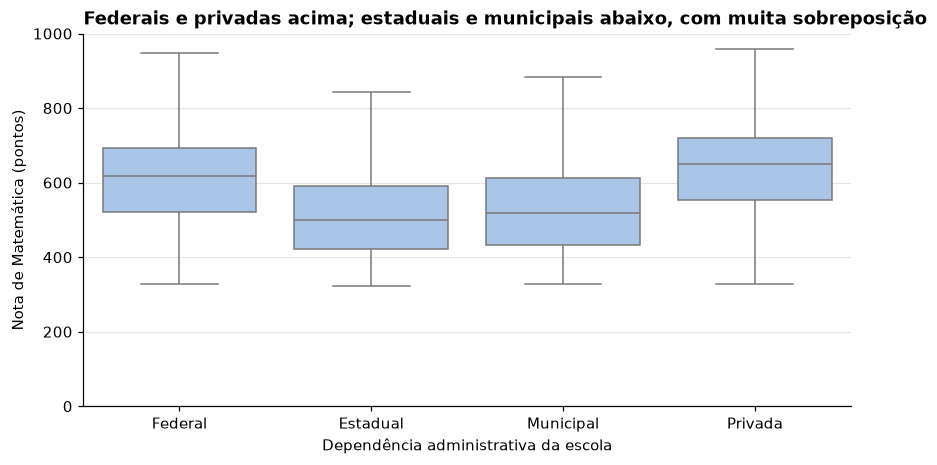

In [22]:
DEPS = ['Federal', 'Estadual', 'Municipal', 'Privada']
base_dep = base[base.dependencia.notna()]                     # só quem tem a dependência informada
display(base_dep.groupby('dependencia').NU_NOTA_MT.agg(n='count', média='mean', mediana='median', dp='std').loc[DEPS].round(1))

fig, ax = plt.subplots(figsize=(9, 4.4))
sns.boxplot(data=base_dep, x='dependencia', y='NU_NOTA_MT', order=DEPS, color='#9ec5f4', showfliers=False, ax=ax)
ax.set_ylim(0, 1000)
ax.set_xlabel('Dependência administrativa da escola')
ax.set_ylabel('Nota de Matemática (pontos)')
ax.set_title('Federais e privadas acima; estaduais e municipais abaixo, com muita sobreposição')
plt.show()

## 4.5 Território: o gráfico honesto

O território aqui é o **local de prova**, disponível para todos. Primeiro, as cinco regiões, para mostrar o erro gráfico mais comum: o **eixo truncado** (slide 42).

### Prompt para a IA — o gráfico honesto

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um analista que prepara gráficos para a diretoria.

Contexto: DataFrame base com a base de análise do ENEM 2023. Colunas: NU_NOTA_MT e SG_UF_PROVA (UF do local de prova). Vou agrupar as UFs nas 5 regiões do IBGE.

Pergunta: Como mostrar a média de MT por região sem exagerar nem esconder a diferença?

Tarefa: (1) Calcule n e média de MT por região. (2) Faça dois gráficos de barras lado a lado: um com o eixo começando em 490 (o erro a evitar) e outro com o eixo de 0 a 1.000, com valor e n em cada barra. (3) Calcule a razão real entre a maior e a menor média e a razão aparente no gráfico truncado.

Restrições: Títulos que dizem a conclusão; eixos com unidade; sem 3D; matplotlib; só código.

Formato: Código comentado; depois, o checklist do gráfico honesto aplicado ao gráfico corrigido.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- A razão real entre a maior e a menor média é ≈ 1,16 (Sudeste ÷ Norte); a aparente no eixo truncado é muitas vezes maior.
- O gráfico corrigido começa em zero e mostra o n de cada barra.
- O mapeamento UF → região tem as 27 UFs.

*Slides v11: 42–43.*

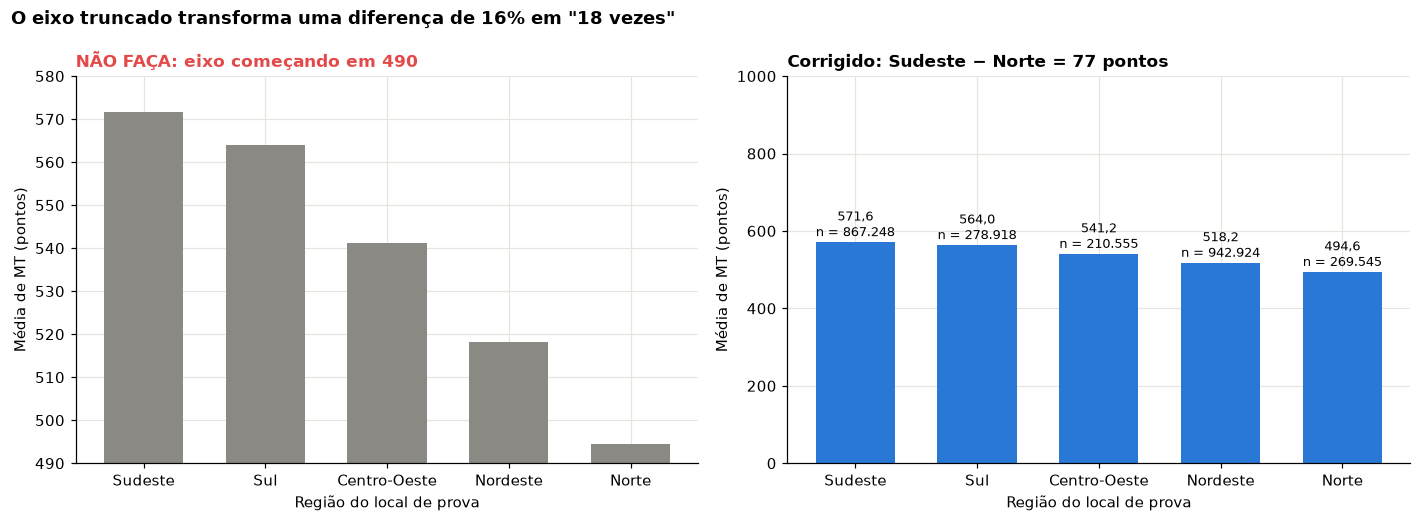

27 UFs mapeadas? True | razão real = 1,16 | razão aparente = 17,8


In [23]:
reg = base.groupby('regiao').NU_NOTA_MT.agg(n='count', média='mean').sort_values('média', ascending=False)
PISO = 490                                                     # onde o eixo "truncado" começa
razao_real = reg.média.iloc[0] / reg.média.iloc[-1]            # maior média ÷ menor média
razao_aparente = (reg.média.iloc[0] - PISO) / (reg.média.iloc[-1] - PISO)   # razão entre as ALTURAS das barras com o eixo em 490

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8))
eixos[0].bar(reg.index, reg.média, color=CINZA, width=0.65)
eixos[0].set_ylim(PISO, 580)
eixos[0].set_title(f'NÃO FAÇA: eixo começando em {PISO}', fontsize=11, color=VERMELHO)
eixos[1].bar(reg.index, reg.média, color=AZUL, width=0.65)
eixos[1].set_ylim(0, 1000)
for i, (v, n) in enumerate(zip(reg.média, reg.n)):
    eixos[1].text(i, v + 15, f'{br(v)}\nn = {br(n, 0)}', ha='center', fontsize=8.5)
eixos[1].set_title(f'Corrigido: {reg.index[0]} − {reg.index[-1]} = {br(reg.média.iloc[0] - reg.média.iloc[-1], 0)} pontos', fontsize=11)
for ax in eixos:
    ax.set_xlabel('Região do local de prova'); ax.set_ylabel('Média de MT (pontos)')
fig.suptitle(f'O eixo truncado transforma uma diferença de {br(100 * (razao_real - 1), 0)}% em "{razao_aparente:.0f} vezes"',
             x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()
print(f'27 UFs mapeadas? {len(REGIAO) == 27} | razão real = {br(razao_real, 2)} | razão aparente = {br(razao_aparente, 1)}')

Agora as 27 UFs. Para enxergar diferenças pequenas **sem truncar o eixo**, o gráfico mostra a diferença de cada UF para a média nacional: o zero é a média do país, e o comprimento de cada barra é a distância até ela.

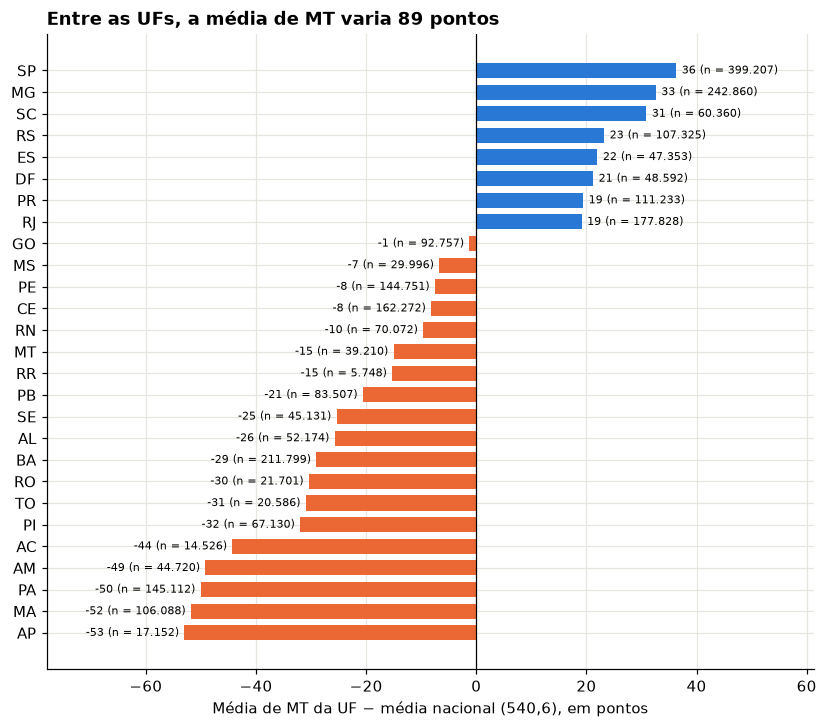

In [24]:
MEDIA_BR = base.NU_NOTA_MT.mean()
uf = base.groupby('SG_UF_PROVA').NU_NOTA_MT.agg(n='count', média='mean').sort_values('média')
uf['diferença'] = uf['média'] - MEDIA_BR

fig, ax = plt.subplots(figsize=(9, 7.5))
cores = [AZUL if d > 0 else LARANJA for d in uf['diferença']]            # azul acima da média, laranja abaixo
ax.barh(uf.index, uf['diferença'], color=cores, height=0.7)
ax.axvline(0, color='black', lw=0.8)
for i, (d, n) in enumerate(zip(uf['diferença'], uf.n)):
    ax.text(d + (1 if d > 0 else -1), i, f'{br(d, 0)} (n = {br(n, 0)})', va='center', ha='left' if d > 0 else 'right', fontsize=7.5)
ax.set_xlim(uf['diferença'].min() - 25, uf['diferença'].max() + 25)
ax.set_xlabel(f'Média de MT da UF − média nacional ({br(MEDIA_BR)}), em pontos')
ax.set_title(f"Entre as UFs, a média de MT varia {br(uf['média'].max() - uf['média'].min(), 0)} pontos")
plt.show()

## 4.6 Como medir o tamanho de uma diferença: o d de Cohen

"Homens têm 46 pontos a mais em MT" é grande ou pequeno? Depende de quanto as notas variam. O **d de Cohen** divide a diferença de médias pelo desvio padrão dos dois grupos juntos: diz **quantos desvios padrão** separam os grupos. Referências usuais (Cohen, 1988): 0,2 pequeno, 0,5 médio, 0,8 grande. O plano fixou d = 0,2 como o mínimo que importa.

Como o d será usado várias vezes, vale escrevê-lo como uma **função**: um bloco de código com nome, que recebe as notas dos dois grupos e devolve o d.

In [25]:
def d_cohen(a, b):
    # a e b: notas dos dois grupos
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    # desvio padrão "combinado": média das variâncias dos dois grupos, ponderada pelo tamanho de cada um
    dp_comb = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / dp_comb

# Exemplo: privadas × públicas em MT
print(f"d (privada × pública, MT) = {br(d_cohen(base.loc[base.TP_ESCOLA == 3, 'NU_NOTA_MT'], base.loc[base.TP_ESCOLA == 2, 'NU_NOTA_MT']), 2)}")

d (privada × pública, MT) = 1,09


## 4.7 Sexo: quem vai melhor depende da prova

In [26]:
sexo_notas = base.groupby('sexo')[NOTAS].mean().rename(columns=NOME_NOTA).T     # .T vira a tabela: provas nas linhas
sexo_notas['homens − mulheres'] = sexo_notas['Masculino'] - sexo_notas['Feminino']
sexo_notas['d'] = [d_cohen(base.loc[base.TP_SEXO == 'M', n], base.loc[base.TP_SEXO == 'F', n]) for n in NOTAS]
sexo_notas.round(2)

sexo,Feminino,Masculino,homens − mulheres,d
Ciências da Natureza,492.21,514.98,22.77,0.29
Ciências Humanas,525.47,536.61,11.14,0.13
Linguagens,521.46,525.92,4.46,0.06
Matemática,522.78,569.33,46.54,0.38
Redação,663.74,627.34,-36.40,-0.21


"Homens vão melhor no ENEM" é uma frase falsa enquanto não diz **qual prova**: a diferença é a favor dos homens em Matemática e a favor das mulheres na Redação (slide 33).

## 4.8 Cor/raça e renda andam juntas

In [27]:
ORDEM_COR = ['Branca', 'Amarela', 'Não declarado', 'Parda', 'Preta', 'Indígena']
cor_tab = base.groupby('cor').NU_NOTA_MT.agg(n='count', média='mean', dp='std').loc[ORDEM_COR]
# % de cada grupo com renda familiar até R$ 2.640 (faixas A a D)
cor_tab['% com renda até R$ 2.640'] = 100 * base.Q006.isin(['A', 'B', 'C', 'D']).groupby(base.cor).mean()
mt_brancos = base.loc[base.cor == 'Branca', 'NU_NOTA_MT']
cor_tab['d (vs. Branca)'] = [d_cohen(base.loc[base.cor == c, 'NU_NOTA_MT'], mt_brancos) for c in ORDEM_COR]
cor_tab.round(2)

,n,média,dp,% com renda até R$ 2.640,d (vs. Branca)
cor,,,,,
Branca,1119070,577.22,127.17,44.71,0.00
Amarela,40854,544.93,138.31,61.70,-0.25
Não declarado,31436,544.45,130.28,61.95,-0.26
Parda,1062833,514.27,115.68,72.67,-0.52
Preta,301740,499.61,107.78,76.65,-0.63
Indígena,13257,470.51,101.05,83.46,-0.84


A descritiva mostra a associação, mas **não separa** cor/raça de renda: a fração de famílias com renda até R$ 2.640 vai de cerca de 45% entre brancos a 77% entre pretos (slide 34).

## 4.9 Comparar dentro de cada faixa de renda

Se renda e escola andam juntas, a diferença "privada − pública" mistura as duas coisas. Um jeito simples de separar: comparar **dentro de cada faixa de renda**. Se a diferença sobrevive com a renda fixada, ela não é só renda. É o primeiro passo do que a regressão faz na Etapa 8, com vários fatores de uma vez.

### Prompt para a IA — comparar dentro das faixas de renda

O prompt que levaria ao código desta seção, no molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**.

```text
Papel: Você é um analista de dados que escreve código Python claro e auditável.

Contexto: DataFrame base com a base de análise do ENEM 2023. Colunas: NU_NOTA_MT; renda_4 (renda familiar em 4 faixas ordenadas); escola ("Pública", "Privada" ou "Não respondeu"; só concluintes de 2023 informam); cor (cor/raça autodeclarada, com rótulos). Dados observacionais.

Pergunta: A diferença de média de MT entre privadas e públicas, e entre brancos e pretos, continua quando se compara gente da mesma faixa de renda?

Tarefa: (1) Para cada faixa de renda_4, calcule a média de MT e o n de cada grupo e a diferença entre eles. (2) Acrescente uma linha com a diferença no total, sem separar por renda. (3) Faça isso para privada × pública (só quem informou escola) e para branca × preta.

Restrições: Use pivot_table ou groupby, sem laços. Mostre o n de cada casela. Não use "efeito" nem "causa". Só código, sem números.

Formato: Código comentado em português; depois, como ler a tabela e uma limitação do método (controla um fator de cada vez).
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- A linha do total bate com a diferença das médias calculada nas seções 4.1 (escola) e 4.8 (cor/raça)?
- O n de cada casela soma o n do grupo?
- A leitura fala em "diminui" ou "permanece", e não em "efeito da escola" ou "efeito da cor".

`pivot_table` monta uma tabela com as faixas de renda nas linhas, os grupos nas colunas e a média de MT em cada casela.

In [28]:
TOTAL = 'TOTAL (sem separar por renda)'
conc_esc = base[base.escola.isin(['Pública', 'Privada'])]          # concluintes de 2023 que informaram a escola
esc = conc_esc.pivot_table(index='renda_4', columns='escola', values='NU_NOTA_MT', aggfunc='mean')
esc.loc[TOTAL] = conc_esc.groupby('escola').NU_NOTA_MT.mean()       # linha extra: as médias sem separar por renda
esc['privada − pública'] = esc['Privada'] - esc['Pública']
display(esc.round(1))

cor = base[base.cor.isin(['Branca', 'Preta'])]
bp = cor.pivot_table(index='renda_4', columns='cor', values='NU_NOTA_MT', aggfunc='mean')
bp.loc[TOTAL] = cor.groupby('cor').NU_NOTA_MT.mean()
bp['branca − preta'] = bp['Branca'] - bp['Preta']
display(bp.round(1))

# O n de cada casela, para saber em quantas pessoas cada média se apoia
display(pd.crosstab(conc_esc.renda_4, conc_esc.escola))
display(pd.crosstab(cor.renda_4, cor.cor))

escola,Privada,Pública,privada − pública
renda_4,,,
1) até R$ 1.320,552.2,475.1,77.1
2) R$ 1.320–3.300,586.7,520.2,66.6
3) R$ 3.300–6.600,622.1,560.4,61.7
4) acima de R$ 6.600,669.0,597.2,71.8
TOTAL (sem separar por renda),633.0,511.2,121.8


cor,Branca,Preta,branca − preta
renda_4,,,
1) até R$ 1.320,501.4,466.9,34.4
2) R$ 1.320–3.300,550.4,508.4,42.0
3) R$ 3.300–6.600,600.9,557.8,43.1
4) acima de R$ 6.600,657.3,599.7,57.6
TOTAL (sem separar por renda),577.2,499.6,77.6


escola,Privada,Pública
renda_4,,
1) até R$ 1.320,11956,328007
2) R$ 1.320–3.300,44668,301689
3) R$ 3.300–6.600,59944,111004
4) acima de R$ 6.600,102639,42934


cor,Branca,Preta
renda_4,,
1) até R$ 1.320,230476,139196
2) R$ 1.320–3.300,371142,113089
3) R$ 3.300–6.600,248518,33256
4) acima de R$ 6.600,268934,16199


**Leitura:** as duas diferenças **diminuem** quando a renda é fixada, mas **não somem**: parte acompanha a renda e parte permanece. A diferença privada − pública cai de 122 pontos no total para algo entre 62 e 77 dentro das faixas; a branca − preta, de 78 para 34 a 58. É uma afirmação de **associação**, não de causa.

## 4.10 Painel: qual dimensão está mais associada a cada nota?

O **η² (eta ao quadrado)** responde: que fração da variação das notas acompanha os grupos? Vai de 0% (as médias dos grupos são iguais) a 100% (toda a variação está entre os grupos, nada dentro deles). A conta compara a variação **entre** as médias dos grupos com a variação **total**.

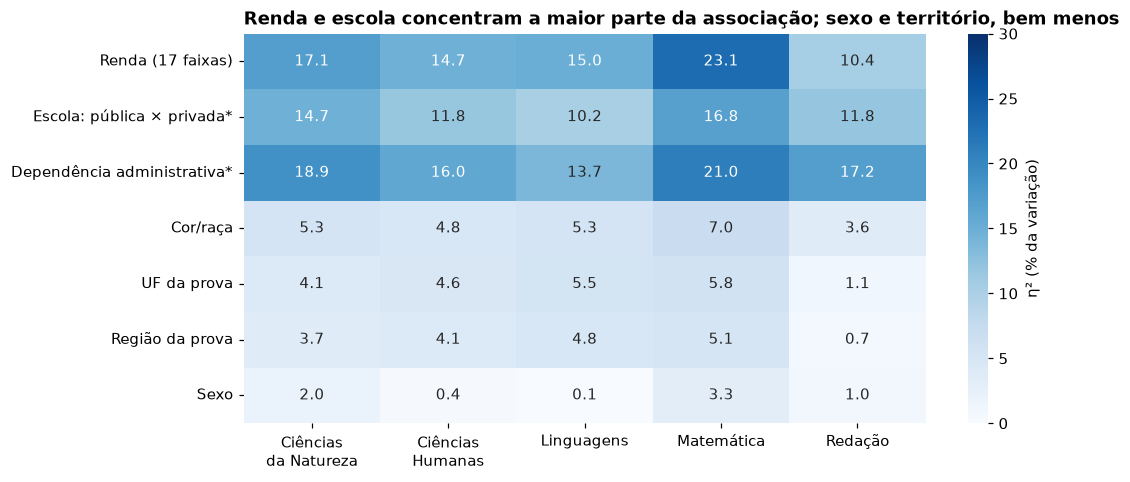

* só entre quem tem a informação (concluintes de 2023 que informaram escola ou dependência).


In [29]:
def eta2(notas, grupos):
    # Fração da variação total das notas que está ENTRE as médias dos grupos
    d = pd.DataFrame({'nota': np.asarray(notas, dtype=float), 'grupo': np.asarray(grupos)})
    media_geral = d.nota.mean()
    g = d.groupby('grupo').nota.agg(['count', 'mean'])                       # n e média de cada grupo
    variacao_entre = (g['count'] * (g['mean'] - media_geral) ** 2).sum()     # o quanto as médias dos grupos se afastam da geral
    variacao_total = ((d.nota - media_geral) ** 2).sum()                     # o quanto cada nota se afasta da geral
    return variacao_entre / variacao_total

# Cada dimensão: (nome, tabela a usar, coluna dos grupos). Escola e dependência só entre quem as informou (*)
dimensoes = [('Renda (17 faixas)', base, 'Q006'), ('Escola: pública × privada*', conc_esc, 'escola'),
             ('Dependência administrativa*', base_dep, 'dependencia'), ('Cor/raça', base, 'cor'),
             ('UF da prova', base, 'SG_UF_PROVA'), ('Região da prova', base, 'regiao'), ('Sexo', base, 'sexo')]
painel = pd.DataFrame({NOME_NOTA[n]: {nome: 100 * eta2(tab[n], tab[col]) for nome, tab, col in dimensoes} for n in NOTAS})

fig, ax = plt.subplots(figsize=(10, 4.6))
sns.heatmap(painel, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=30, cbar_kws={'label': 'η² (% da variação)'}, ax=ax)
ax.set_xticklabels([c.replace(' ', '\n', 1) for c in painel.columns], rotation=0)
ax.set_ylabel('')
ax.set_title('Renda e escola concentram a maior parte da associação; sexo e território, bem menos')
plt.show()
print('* só entre quem tem a informação (concluintes de 2023 que informaram escola ou dependência).')

**Leitura:** em Matemática, a renda acompanha cerca de 23% da variação das notas; cor/raça, 7%; a UF, menos de 6%; o sexo, 3%. Mesmo a dimensão mais forte deixa a maior parte da variação **dentro** dos grupos: em qualquer faixa de renda há notas altas e baixas.

---
# Etapa 5 — Probabilidade: qual condicional estamos lendo?

> *"Probabilidade responde: se o mundo fosse assim, o que eu veria? Inferência responde o inverso: vi isto, como é o mundo?"*

## 5.1 A inversão da condicional

A notação **P(A | B)** se lê "probabilidade de A **dado** B": a chance de A entre os que têm B. "Nota alta" = MT ≥ 700 (fixado no plano). O erro clássico é trocar P(nota alta | renda alta) por P(renda alta | nota alta).

### Prompt para a IA — a probabilidade condicional

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico que explica probabilidades para gestores.

Contexto: DataFrame base com a base de análise do ENEM 2023. Colunas: NU_NOTA_MT; Q006 (renda familiar, 17 faixas A a Q; K a Q = acima de R$ 9.240); TP_COR_RACA (1 branca, 2 preta, 3 parda; autodeclarada).

Pergunta: Ter renda alta e ter nota alta (MT ≥ 700): P(nota alta | renda alta) é o mesmo que P(renda alta | nota alta)? E com cor/raça?

Tarefa: (1) Calcule a taxa de base P(renda K–Q) e P(MT ≥ 700). (2) Calcule as duas condicionais e a tabela 2 × 2 com os totais. (3) Repita com "preto ou pardo" no lugar de "renda K–Q", e P(MT ≥ 700 | branco).

Restrições: Use máscaras booleanas, sem laços. Nomeie cada probabilidade com a notação P(A | B). Não use linguagem causal. Só código.

Formato: Código comentado; depois, uma frase correta e uma frase errada (inversão da condicional) para um relatório.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- A tabela 2 × 2 soma 2.569.190.
- Regra de Bayes: P(renda | nota) = P(nota | renda) × P(renda) ÷ P(nota) dá o mesmo que a contagem direta.
- As duas condicionais diferem quando as taxas de base diferem.

*Slides v11: 49, 59.*

In [30]:
rico = base.Q006.isin(list('KLMNOPQ'))         # máscara: renda acima de R$ 9.240 (faixas K a Q)
alta = base.NU_NOTA_MT >= NOTA_ALTA            # máscara: nota alta em MT
# A média de uma máscara True/False é a proporção de True; dentro de [ ], filtra-se o grupo
print(f'P(renda K–Q) = {br(100 * rico.mean())}%   <- a "taxa de base": quão comum é a renda alta')
print(f'P(MT ≥ 700) = {br(100 * alta.mean())}%')
print(f'P(MT ≥ 700 | renda K–Q) = {br(100 * alta[rico].mean())}%   <- entre os de renda alta, quantos têm nota alta')
print(f'P(renda K–Q | MT ≥ 700) = {br(100 * rico[alta].mean())}%   <- entre as notas altas, quantas são de renda alta')
pd.crosstab(rico.map({True: 'renda K–Q', False: 'demais faixas'}), alta.map({True: 'MT ≥ 700', False: 'MT < 700'}),
            margins=True, margins_name='Total')

P(renda K–Q) = 9,7%   <- a "taxa de base": quão comum é a renda alta
P(MT ≥ 700) = 12,0%
P(MT ≥ 700 | renda K–Q) = 41,0%   <- entre os de renda alta, quantos têm nota alta
P(renda K–Q | MT ≥ 700) = 33,2%   <- entre as notas altas, quantas são de renda alta


NU_NOTA_MT,MT < 700,MT ≥ 700,Total
Q006,,,
demais faixas,2114404,205611,2320015
renda K–Q,147072,102103,249175
Total,2261476,307714,2569190


In [31]:
# A mesma lógica com cor/raça
pp = base.TP_COR_RACA.isin([2, 3])             # preto ou pardo
branco = base.TP_COR_RACA == 1
print(f'P(preto ou pardo) = {br(100 * pp.mean())}%   (taxa de base)')
print(f'P(MT ≥ 700 | preto ou pardo) = {br(100 * alta[pp].mean())}% | P(MT ≥ 700 | branco) = {br(100 * alta[branco].mean())}%')
print(f'P(preto ou pardo | MT ≥ 700) = {br(100 * pp[alta].mean())}%')

# Verificação independente pela regra de Bayes: outro caminho, mesmo resultado
bayes = alta[rico].mean() * rico.mean() / alta.mean()
print(f'\nBayes: P(renda K–Q | MT ≥ 700) = P(MT ≥ 700 | renda) × P(renda) ÷ P(MT ≥ 700) = {br(100 * bayes)}%')

P(preto ou pardo) = 53,1%   (taxa de base)
P(MT ≥ 700 | preto ou pardo) = 6,6% | P(MT ≥ 700 | branco) = 18,4%
P(preto ou pardo | MT ≥ 700) = 29,4%

Bayes: P(renda K–Q | MT ≥ 700) = P(MT ≥ 700 | renda) × P(renda) ÷ P(MT ≥ 700) = 33,2%


**Leitura:** 41% dos de renda alta têm nota alta, mas só um terço das notas altas é de renda alta, porque renda alta é rara (taxa de base de 9,7%). *Frase certa:* "entre os estudantes de renda acima de R$ 9.240, 41% tiraram 700 ou mais em MT". *Frase errada:* "41% das notas altas são de estudantes ricos".

## 5.2 O que esperar do acaso: a binomial do chute

Uma prova de 45 itens com 5 alternativas, marcada inteiramente ao acaso: cada item tem 20% de chance de acerto. O número de acertos segue uma distribuição **binomial**, com média 45 × 0,2 = 9 acertos. Quanto é "sorte demais"? (slide 52)

### Prompt para a IA — a binomial

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico que confere cálculos de probabilidade por simulação.

Contexto: Uma prova do ENEM tem 45 itens de 5 alternativas. Um participante marca todos ao acaso. (Exemplo conceitual: a nota do ENEM usa TRI, não o número de acertos.)

Pergunta: Quantos acertos esperar do puro chute, e qual a chance de chegar a 15 ou a 18 acertos?

Tarefa: (1) Diga qual distribuição modela X = nº de acertos e liste as suposições. (2) Com scipy.stats, calcule E(X), o DP, P(X ≥ 15) e P(X ≥ 18). (3) Simule 100.000 provas com semente 2023 e compare. (4) Para n = 5, 20 e 100 itens, desenhe a binomial exata e a normal com a mesma média e variância, e compare P(X ≤ nπ) exata e aproximada (com correção de continuidade).

Restrições: Não calcule de cabeça: só código. Diga se a simulação deve coincidir com o exato e qual a margem esperada.

Formato: Código comentado; depois, como ler P(X ≥ 18) para quem suspeita de "chute premiado".
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- E(X) = 45 × 0,2 = 9; DP = √(45 × 0,2 × 0,8) ≈ 2,68 (conta à mão).
- Exato e simulado diferem menos que ≈ 2 × √(p(1−p)/100.000).
- P(X ≥ 15) usa sf(14), não sf(15): o erro de "um a menos" é o mais comum.

*Slides v11: 51–52, 56.*

Acertos esperados = 9 | desvio padrão = 2,68
P(15 ou mais acertos) = 2,50% (fórmula) | 2,54% (simulação)
P(18 ou mais acertos) = 0,17% (fórmula) | 0,17% (simulação)


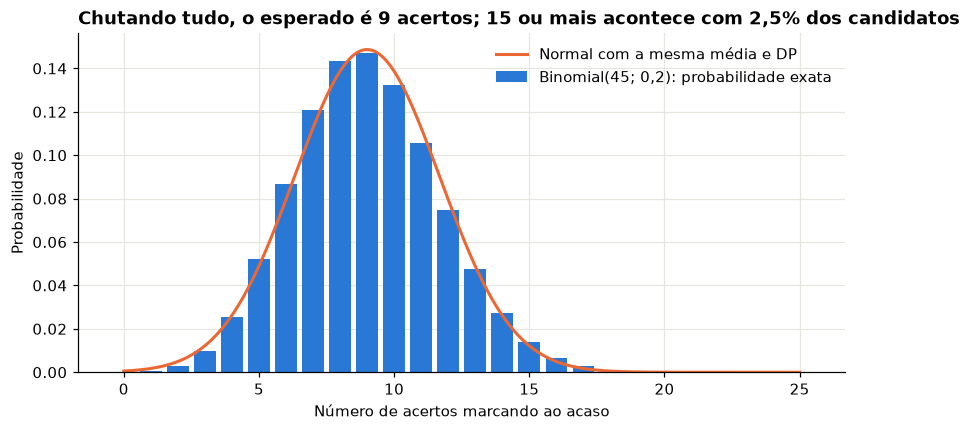

In [32]:
N_ITENS, P_ACERTO = 45, 0.2
chute = stats.binom(N_ITENS, P_ACERTO)                      # a distribuição binomial com esses parâmetros
print(f'Acertos esperados = {br(chute.mean(), 0)} | desvio padrão = {br(chute.std(), 2)}')

rng = np.random.default_rng(SEMENTE)                        # gerador de sorteios desta seção
simulados = rng.binomial(N_ITENS, P_ACERTO, size=100_000)   # 100 mil candidatos "chutando" a prova inteira
for k in (15, 18):
    exato = chute.sf(k - 1)                                  # P(X ≥ k) = 1 − P(X ≤ k − 1)
    print(f'P({k} ou mais acertos) = {br(100 * exato, 2)}% (fórmula) | {br(100 * (simulados >= k).mean(), 2)}% (simulação)')

fig, ax = plt.subplots(figsize=(9, 4))
k = np.arange(0, 26)
ax.bar(k, chute.pmf(k), color=AZUL, width=0.8, label='Binomial(45; 0,2): probabilidade exata')
xs = np.linspace(0, 25, 300)
ax.plot(xs, stats.norm.pdf(xs, chute.mean(), chute.std()), color=LARANJA, lw=2, label='Normal com a mesma média e DP')
ax.set_xlabel('Número de acertos marcando ao acaso'); ax.set_ylabel('Probabilidade')
ax.set_title('Chutando tudo, o esperado é 9 acertos; 15 ou mais acontece com 2,5% dos candidatos')
ax.legend()
plt.show()

Com 45 itens, a binomial já tem forma de sino e a normal a aproxima bem (regra prática: nπ ≥ 5 e n(1−π) ≥ 5). *No ENEM real, a nota é calculada pela TRI; a binomial aqui serve para pensar no que o acaso produz.*

## 5.3 A distribuição normal nas notas: a regra 68-95-99,7

Se as notas seguissem uma normal, 68,3% delas ficariam a menos de 1 desvio padrão da média, 95,4% a menos de 2 e 99,7% a menos de 3. O **escore z** mede essa distância: z = (nota − média) ÷ desvio padrão.

### Prompt para a IA — a normal e o Teorema Central do Limite

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico que testa modelos contra os dados.

Contexto: DataFrame base (base de análise do ENEM 2023) com as cinco notas NU_NOTA_CN, NU_NOTA_CH, NU_NOTA_LC, NU_NOTA_MT e NU_NOTA_REDACAO; DataFrame insc com todos os inscritos e TP_PRESENCA_MT (1 = presente).

Pergunta: A regra 68-95-99,7 da normal vale para as notas? E a média de amostras de uma variável 0/1 fica normal quando n cresce?

Tarefa: (1) Para cada nota, calcule média, DP, assimetria e o % de participantes a menos de 1, 2 e 3 DP da média. (2) Desenhe o histograma de MT com a normal de mesma média e DP. (3) Com a presença em MT (0/1), sorteie 5.000 amostras de n = 5, 30 e 400 (semente 2023), desenhe o histograma das proporções e compare o DP delas com √(p(1−p)/n).

Restrições: Use o DP populacional (ddof = 0) na regra 68-95-99,7, porque a base é tratada como população. Só código.

Formato: Código comentado; depois, em 3 frases, onde a normal é um bom modelo e onde não é.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- Na normal: 68,3% | 95,4% | 99,7% (`stats.norm.cdf(1) − stats.norm.cdf(−1)` etc.).
- MT é mais achatada: bem menos de 68% a 1 DP.
- O DP das proporções simuladas fica perto de √(p(1−p)/n) em cada n (seção 5.4).

*Slides v11: 53–58.*

In [33]:
regra = {}
for n in NOTAS:
    x = base[n].to_numpy()
    z = (x - x.mean()) / x.std()                             # escore z de cada participante (a base é a população: ddof = 0)
    regra[NOME_NOTA[n]] = {'média': x.mean(), 'dp': x.std(), 'assimetria': stats.skew(x),
                           '|z| < 1 (%)': 100 * (abs(z) < 1).mean(), '|z| < 2 (%)': 100 * (abs(z) < 2).mean(),
                           '|z| < 3 (%)': 100 * (abs(z) < 3).mean()}
print('Na normal: 68,3% | 95,4% | 99,7%')
pd.DataFrame(regra).T.round(2)

Na normal: 68,3% | 95,4% | 99,7%


,média,dp,assimetria,|z| < 1 (%),|z| < 2 (%),|z| < 3 (%)
Ciências da Natureza,500.93,78.77,0.35,68.21,95.39,99.57
Ciências Humanas,529.74,83.93,-0.26,67.82,95.18,99.97
Linguagens,523.17,72.26,-0.31,68.80,95.19,99.74
Matemática,540.60,124.91,0.37,62.51,97.39,99.88
Redação,649.81,174.88,-0.05,64.72,97.88,99.98


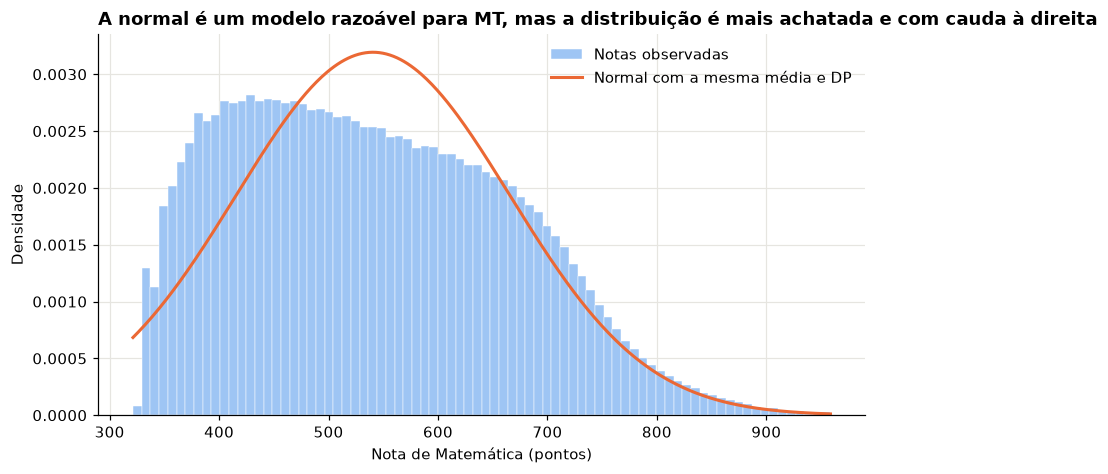

P(MT > 600): pela normal = 31,7% | observado = 32,7%
P(MT > 700): pela normal = 10,1% | observado = 12,0%
P(MT > 800): pela normal = 1,9% | observado = 2,2%


In [34]:
mt = base.NU_NOTA_MT.to_numpy()
MU, SIGMA = mt.mean(), mt.std()                              # média e desvio padrão "verdadeiros" (a população do estudo)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(mt, bins=80, density=True, color='#9ec5f4', edgecolor='white', linewidth=0.3, label='Notas observadas')
xs = np.linspace(mt.min(), mt.max(), 400)
ax.plot(xs, stats.norm.pdf(xs, MU, SIGMA), color=LARANJA, lw=2, label='Normal com a mesma média e DP')
ax.set_xlabel('Nota de Matemática (pontos)'); ax.set_ylabel('Densidade')
ax.set_title('A normal é um modelo razoável para MT, mas a distribuição é mais achatada e com cauda à direita')
ax.legend()
plt.show()
for corte in (600, 700, 800):
    print(f'P(MT > {corte}): pela normal = {br(100 * stats.norm.sf(corte, MU, SIGMA))}% | observado = {br(100 * (mt > corte).mean())}%')

**Leitura:** a regra funciona bem para CN, CH e LC; Matemática é mais achatada (só 62,5% a menos de 1 DP). A normal é um **modelo**, não um fato: ela subestima a fração de notas acima de 700. Para decisões que dependem da cauda (bolsas, cortes), use a proporção observada.

## 5.4 O Teorema Central do Limite (TCL)

A presença na prova é uma variável **nada normal**: só vale 0 (faltou) ou 1 (presente). Mesmo assim, se sortearmos muitas amostras e calcularmos a proporção de presentes em cada uma, essas proporções formam um **sino**, cada vez mais estreito conforme n cresce. Esse é o TCL, e é por causa dele que intervalos de confiança e testes funcionam (Etapas 6 e 7). O espalhamento das proporções tem nome: **erro padrão**, e vale √(p(1−p)/n).

n =   5: espalhamento simulado = 0,2074 | fórmula √(p(1−p)/n) = 0,2078
n =  30: espalhamento simulado = 0,0825 | fórmula √(p(1−p)/n) = 0,0849
n = 400: espalhamento simulado = 0,0232 | fórmula √(p(1−p)/n) = 0,0232


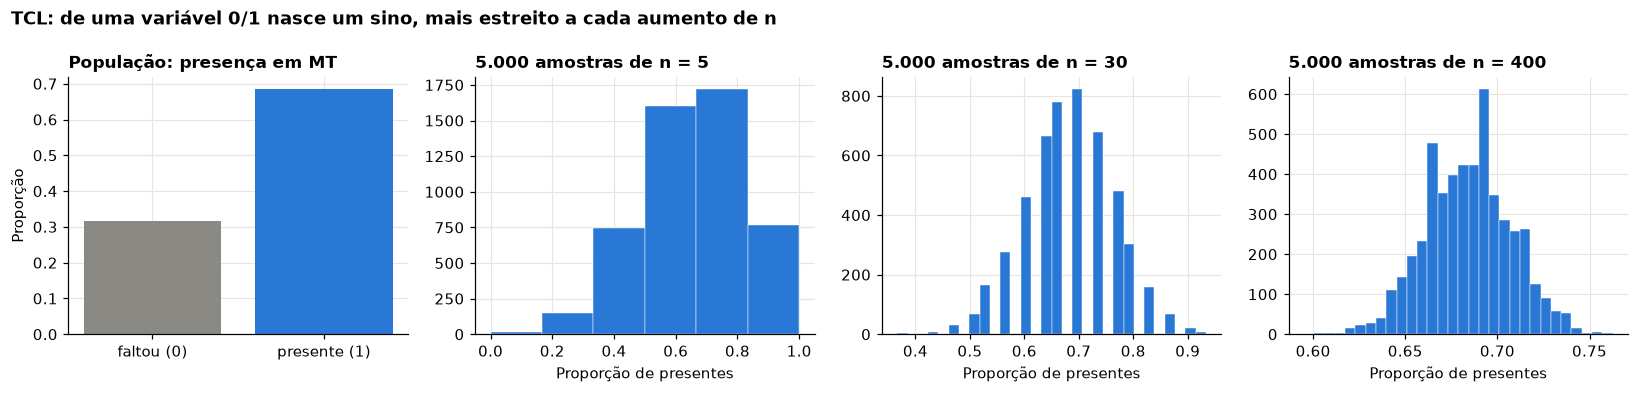

In [35]:
rng = np.random.default_rng(SEMENTE)                         # gerador desta seção
presenca = (insc.TP_PRESENCA_MT == 1).astype(int).to_numpy() # 1 = presente, 0 = não; todos os inscritos
p_pop = presenca.mean()

fig, eixos = plt.subplots(1, 4, figsize=(15, 3.6))
eixos[0].bar(['faltou (0)', 'presente (1)'], [1 - p_pop, p_pop], color=[CINZA, AZUL])
eixos[0].set_title('População: presença em MT', fontsize=11); eixos[0].set_ylabel('Proporção')
for ax, n in zip(eixos[1:], (5, 30, 400)):
    proporcoes = rng.choice(presenca, size=(5000, n)).mean(axis=1)    # 5.000 amostras de tamanho n; a proporção de cada uma
    ax.hist(proporcoes, bins=30 if n > 5 else 6, color=AZUL, edgecolor='white', linewidth=0.3)
    ax.set_title(f'5.000 amostras de n = {n}', fontsize=11); ax.set_xlabel('Proporção de presentes')
    print(f'n = {n:3d}: espalhamento simulado = {br(proporcoes.std(ddof=1), 4)} | fórmula √(p(1−p)/n) = {br(np.sqrt(p_pop * (1 - p_pop) / n), 4)}')
fig.suptitle('TCL: de uma variável 0/1 nasce um sino, mais estreito a cada aumento de n', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

---
# Etapa 6 — Amostragem: e se só tivéssemos uma amostra?

> *"Com sorteio, o erro se mede; sem sorteio, o erro não se mede."*

Aqui a base de análise faz o papel de **população**: conhecemos a média verdadeira de MT (μ ≈ 540,6) e podemos ver o quanto cada amostra erra.

## 6.1 Erro padrão: a lei da raiz de n

### Prompt para a IA — o erro padrão e o intervalo de confiança

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico que mostra o erro amostral por simulação.

Contexto: DataFrame base com a base de análise do ENEM 2023 (2.569.190 participantes), que vou tratar como população. Coluna: NU_NOTA_MT.

Pergunta: Quão perto uma amostra aleatória chega da média verdadeira de MT, e como ler o intervalo de confiança?

Tarefa: (1) Calcule μ e σ da população e o erro padrão teórico σ/√n para n = 100, 400 e 1.600. (2) Sorteie, com semente 2023, uma amostra aleatória simples de n = 400 e calcule a média e o IC95% pela t. (3) Sorteie 1.000 amostras de n = 400 e compare o DP das 1.000 médias com σ/√n. (4) Sorteie 100 amostras de n = 50, calcule o IC95% de cada uma e conte quantos contêm μ; desenhe os 100 intervalos.

Restrições: Use o DP amostral (ddof = 1) no IC. Não use a frase "95% de probabilidade de μ estar no intervalo". Só código.

Formato: Código comentado; depois, a leitura correta e a leitura errada de um IC de 95%.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- σ/√n com σ = 124,91: 12,5 (n = 100), 6,25 (n = 400), 3,1 (n = 1.600).
- O DP das 1.000 médias fica perto de 6,25 (seção 6.3).
- Cerca de 95 dos 100 intervalos contêm μ (seção 6.4; o número exato varia com a semente).
- Quadruplicar n divide o erro padrão por 2.

*Slides v11: 63–68, 74.*

O **erro padrão** (EP) é o tamanho típico do erro de uma média amostral: EP = σ / √n. Como n está dentro de uma raiz, **quadruplicar a amostra só divide o erro por 2**.

In [36]:
print(f'População: N = {br(len(mt), 0)} | μ = {br(MU, 2)} | σ = {br(SIGMA, 2)}')
pd.DataFrame({'n': [100, 400, 1600], 'erro padrão σ/√n (pontos)': [SIGMA / np.sqrt(n) for n in (100, 400, 1600)]}).set_index('n').round(2)

População: N = 2.569.190 | μ = 540,60 | σ = 124,91


,erro padrão σ/√n (pontos)
n,
100,12.49
400,6.25
1600,3.12


## 6.2 Uma amostra e o seu intervalo de confiança

Na vida real, o analista tem **uma** amostra. A partir dela calcula a média e um **intervalo de confiança de 95%** (IC95%): média ± t × S/√n, onde S é o desvio padrão da amostra e t ≈ 2 (o valor exato vem da distribuição t de Student). Como o IC será calculado várias vezes daqui em diante, ele vira uma função.

In [37]:
def ic_media(x, confianca=0.95):
    # Devolve a média da amostra e os limites do intervalo de confiança: média ± t · S/√n
    x = np.asarray(x, dtype=float)
    n, media = len(x), x.mean()
    ep = x.std(ddof=1) / np.sqrt(n)                          # erro padrão estimado com o S da amostra
    t = stats.t.ppf((1 + confianca) / 2, n - 1)              # ≈ 1,97 para n = 400
    return media, media - t * ep, media + t * ep

rng = np.random.default_rng(SEMENTE)                         # gerador desta seção (vale também para 6.3)
amostra = rng.choice(mt, size=400, replace=False)            # amostra aleatória simples de 400 participantes
m, inf, sup = ic_media(amostra)
print(f'Amostra de n = 400: média = {br(m)} | IC95% = [{br(inf)}; {br(sup)}]')
print(f'Erro desta amostra = {br(m - MU)} pontos | o IC contém a média verdadeira ({br(MU, 2)})? {inf <= MU <= sup}')

Amostra de n = 400: média = 539,7 | IC95% = [527,5; 551,9]
Erro desta amostra = -0,9 pontos | o IC contém a média verdadeira (540,60)? True


## 6.3 1.000 amostras, 1.000 médias

Repetindo o sorteio mil vezes, vemos a **distribuição das médias amostrais**: em torno da média verdadeira, com espalhamento igual ao erro padrão.

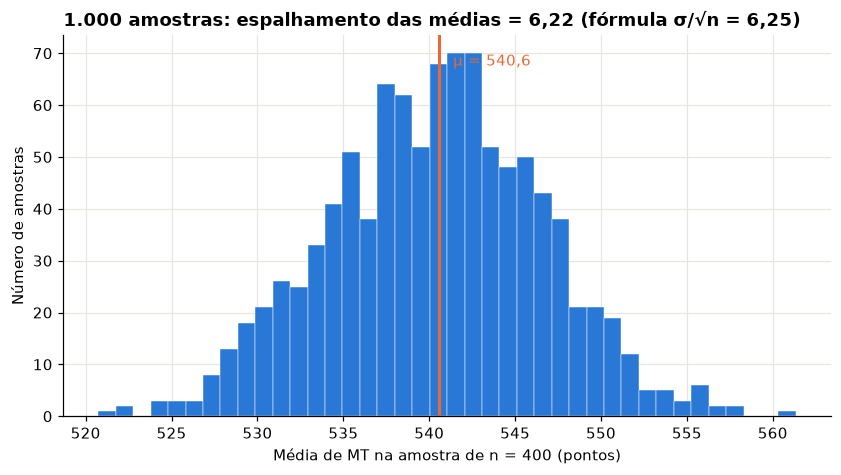

In [38]:
medias_400 = rng.choice(mt, size=(1000, 400)).mean(axis=1)   # 1.000 amostras de 400 (uma por linha); a média de cada uma

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(medias_400, bins=40, color=AZUL, edgecolor='white', linewidth=0.3)
ax.axvline(MU, color=LARANJA, lw=2)
ax.text(MU + 0.5, ax.get_ylim()[1] * 0.92, f' μ = {br(MU)}', color=LARANJA)
ax.set_xlabel('Média de MT na amostra de n = 400 (pontos)'); ax.set_ylabel('Número de amostras')
ax.set_title(f'1.000 amostras: espalhamento das médias = {br(medias_400.std(ddof=1), 2)} (fórmula σ/√n = {br(SIGMA / 20, 2)})')
plt.show()

## 6.4 Como ler um intervalo de confiança

100 amostras de n = 50, cada uma com o seu IC95%. Quantos "acertam" a média verdadeira?

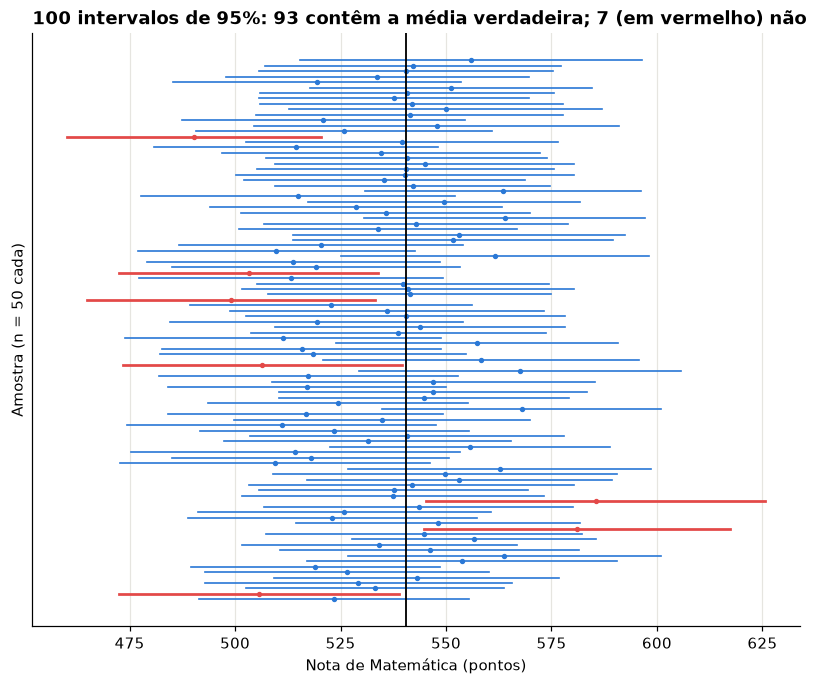

In [39]:
rng = np.random.default_rng(SEMENTE)                          # gerador desta seção
amostras_50 = rng.choice(mt, size=(100, 50))                  # 100 amostras de 50 (uma por linha)
intervalos = [ic_media(a) for a in amostras_50]               # (média, inferior, superior) de cada amostra
acertou = [inf <= MU <= sup for m, inf, sup in intervalos]

fig, ax = plt.subplots(figsize=(9, 7))
for i, (m, inf, sup) in enumerate(intervalos):
    cor = AZUL if acertou[i] else VERMELHO
    ax.plot([inf, sup], [i, i], color=cor, lw=1.1 if acertou[i] else 1.8)
    ax.plot(m, i, 'o', color=cor, ms=2.5)
ax.axvline(MU, color='black', lw=1.2)
ax.set_xlabel('Nota de Matemática (pontos)'); ax.set_ylabel('Amostra (n = 50 cada)'); ax.set_yticks([])
ax.set_title(f'100 intervalos de 95%: {sum(acertou)} contêm a média verdadeira; {100 - sum(acertou)} (em vermelho) não')
plt.show()

**Como ler:** a média verdadeira é fixa; **o intervalo é que varia** de amostra para amostra. *Certo:* "95% dos intervalos construídos assim contêm o parâmetro." *Errado:* "há 95% de probabilidade de μ estar neste intervalo" (este intervalo contém μ ou não; não sabemos qual).

## 6.5 Tamanho da amostra: quanto custa a precisão

Quantos participantes sortear para estimar a média de MT com erro de no máximo ±5 pontos, com 95% de confiança? A fórmula é n = (z · σ / E)², com z ≈ 1,96 e E = erro máximo. Como σ é desconhecido na vida real, usa-se o desvio padrão de uma **amostra-piloto**: a de 400 da seção 6.2.

### Prompt para a IA — o tamanho da amostra

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico que planeja amostras para estimar médias e proporções.

Contexto: Quero estimar a média de MT do ENEM 2023 com 95% de confiança. Tenho uma amostra piloto de 400 participantes (array amostra, nota de MT) e a base inteira (array mt) para conferir por simulação.

Pergunta: Quantos participantes preciso para errar no máximo ±10 pontos? E ±5? E para uma proporção com ±3 pontos percentuais?

Tarefa: (1) Escreva funções n_media(sigma, E) e n_proporcao(E, p = 0,5, N opcional para população finita). (2) Use o DP da amostra piloto como σ. (3) Calcule n para ±10 e ±5 pontos e para a proporção com ±3 p.p. (pior caso π = 0,5). (4) Confira por simulação: com o n de ±5 pontos, sorteie 2.000 amostras e conte quantas erram até 5 pontos.

Restrições: Arredonde n sempre para cima. Mostre a fórmula em comentário. Só código.

Formato: Código comentado; depois, uma frase para o gestor sobre o custo de reduzir o erro pela metade.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- Metade do erro, quatro vezes a amostra (n de ±5 ≈ 4 × n de ±10).
- Proporção, ±3 p.p., π = 0,5: n = 1.068.
- Na simulação, cerca de 95% das amostras erram até 5 pontos.

*Slides v11: 69–70.*

In [40]:
z = stats.norm.ppf(0.975)                                     # 1,96: o z de 95% de confiança
S_PILOTO = amostra.std(ddof=1)                                # desvio padrão da amostra-piloto (seção 6.2)
N_PLANO = int(np.ceil((z * S_PILOTO / ERRO_MAX) ** 2))         # n = (z·S/E)², arredondado para cima
print(f'Desvio padrão da piloto: {br(S_PILOTO, 2)} (o verdadeiro é {br(SIGMA, 2)})')
print(f'n para erro de ±{ERRO_MAX} pontos: {br(N_PLANO, 0)} | para ±10 pontos: {br(np.ceil((z * S_PILOTO / 10) ** 2), 0)}')
print(f'Proporção com erro de ±3 p.p. (pior caso, π = 0,5): n = {br(np.ceil(z ** 2 * 0.25 / 0.03 ** 2), 0)}')

# Verificação por simulação: 2.000 amostras de N_PLANO; em quantas o erro ficou dentro de ±5?
rng = np.random.default_rng(SEMENTE)                          # gerador desta seção
erros = np.abs(rng.choice(mt, size=(2000, N_PLANO)).mean(axis=1) - MU)
print(f'Com n = {br(N_PLANO, 0)}: {br(100 * (erros <= ERRO_MAX).mean())}% das 2.000 amostras erraram até 5 pontos (esperado ≈ 95%)')

Desvio padrão da piloto: 124,06 (o verdadeiro é 124,91)
n para erro de ±5 pontos: 2.366 | para ±10 pontos: 592
Proporção com erro de ±3 p.p. (pior caso, π = 0,5): n = 1.068
Com n = 2.366: 95,2% das 2.000 amostras erraram até 5 pontos (esperado ≈ 95%)


O erro tolerável e a confiança são **decisões do gestor**: metade do erro custa quatro vezes a amostra.

## 6.6 O plano decide onde está a precisão: aleatória simples × estratificada

Com n = 2.366, o Brasil sai com ±5 pontos. E as regiões? Numa **amostra aleatória simples**, cada região recebe uma parte do n proporcional ao seu tamanho, e as regiões pequenas ficam com poucos participantes. Numa **amostra estratificada** com o mesmo n em cada região, a precisão se distribui de outro jeito (slide 66: tipos de amostragem).

### Prompt para a IA — aleatória simples × estratificada por região

O prompt que levaria ao código desta seção, no molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**.

```text
Papel: Você é um estatístico que planeja pesquisas por amostragem.

Contexto: DataFrame base com a base de análise do ENEM 2023, tratada como população (cerca de 2,6 milhões). Colunas: NU_NOTA_MT e regiao (Norte, Nordeste, Centro-Oeste, Sudeste, Sul). Tamanho total da amostra já definido: N_PLANO. Função ic_media(x) devolve média e IC95% pela t.

Pergunta: Com o mesmo n total, como muda a precisão da média de MT de cada região entre uma amostra aleatória simples e uma estratificada com o mesmo n em cada região?

Tarefa: (1) Sorteie uma amostra aleatória simples de N_PLANO (semente 2023) e calcule, por região e para o Brasil, n, média, IC95% e a meia-largura do IC. (2) Sorteie uma amostra estratificada com N_PLANO ÷ 5 em cada região e calcule o mesmo; para o Brasil, use a média ponderada pelo peso de cada região na população e o erro padrão √(Σ W² · S² / n). (3) Coloque as meias-larguras lado a lado. (4) Diga se cada IC contém o valor verdadeiro.

Restrições: Sem reposição. Não use a média simples das regiões como média do Brasil na estratificada. Só código, sem números.

Formato: Código comentado; tabela comparativa; duas frases sobre quando escolher cada plano.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- A soma dos n das regiões dá N_PLANO (ou quase, pelo arredondamento) nos dois planos?
- A meia-largura do Brasil na aleatória simples fica perto de ±5 (o planejado)?
- A média do Brasil na estratificada usa os pesos W das regiões?
- Os valores verdadeiros por região conferem com a seção 4.5.

*Slides v11: 66.*

In [41]:
rng = np.random.default_rng(SEMENTE)                          # gerador desta seção
aas = base.iloc[rng.choice(len(base), size=N_PLANO, replace=False)]           # amostra aleatória simples
n_regiao = N_PLANO // 5
estrat = pd.concat([base[base.regiao == r].sample(n_regiao, random_state=SEMENTE) for r in REGIOES])   # n_regiao em cada região

linhas = []
for r in REGIOES:
    verdade = base.loc[base.regiao == r, 'NU_NOTA_MT'].mean()
    for plano, amostra_r in (('aleatória simples', aas[aas.regiao == r]), ('estratificada', estrat[estrat.regiao == r])):
        m, inf, sup = ic_media(amostra_r.NU_NOTA_MT)
        linhas.append({'região': r, 'plano': plano, 'n': len(amostra_r), '± (meia-largura do IC)': (sup - inf) / 2,
                       'contém o verdadeiro?': inf <= verdade <= sup})
display(pd.DataFrame(linhas).pivot(index='região', columns='plano').loc[REGIOES].round(1))

# Brasil: na aleatória simples, o IC direto; na estratificada, a média ponderada pelos pesos (W) das regiões
m, inf, sup = ic_media(aas.NU_NOTA_MT)
W = base.regiao.value_counts(normalize=True)                  # peso de cada região na população
g = estrat.groupby('regiao').NU_NOTA_MT.agg(['mean', 'var', 'count'])
ep_estrat = np.sqrt((W ** 2 * g['var'] / g['count']).sum())
print(f"Brasil, aleatória simples: {br(m)} ± {br((sup - inf) / 2)} | estratificada: {br((W * g['mean']).sum())} ± {br(1.96 * ep_estrat)} | verdadeiro: {br(MU)}")

n               ± (meia-largura do IC)               contém o verdadeiro?              
plano        aleatória simples estratificada      aleatória simples estratificada    aleatória simples estratificada
região                                                                                                              
Norte                      246           473                   14.4          10.3                 True          True
Nordeste                   879           473                    8.2          11.1                 True          True
Centro-Oeste               177           473                   18.1          11.0                 True          True
Sudeste                    787           473                    8.6          11.0                 True          True
Sul                        277           473                   14.3          10.9                 True          True

Brasil, aleatória simples: 538,9 ± 5,0 | estratificada: 541,2 ± 5,8 | verdadeiro: 540,6


**Leitura:** com o mesmo n total, a estratificada melhora a precisão das regiões pequenas (Norte, Centro-Oeste, Sul), piora a das grandes (Nordeste, Sudeste) e piora um pouco a do Brasil. Se a pergunta da diretoria é sobre as regiões, o plano tem de ser outro; isso se decide **antes** de ir a campo.

## 6.7 Quando a amostra engana: conveniência e seleção

### Prompt para a IA — os vieses

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um revisor de metodologia que procura vieses antes de qualquer conclusão.

Contexto: DataFrame base (base de análise do ENEM 2023, notas e SG_UF_PROVA, IN_TREINEIRO, TP_FAIXA_ETARIA) e DataFrame insc (todos os inscritos, com TP_PRESENCA_MT, Q006, TP_COR_RACA, TP_SEXO).

Pergunta: Quando uma amostra grande ainda engana? Três casos: só ouvir o DF; analisar só quem compareceu; comparar treineiros e demais sem olhar a idade.

Tarefa: (1) Conveniência: sorteie amostras de n = 25 a 3.200 só entre os participantes do DF e do Brasil todo, 500 por n (semente 2023), e mostre a média das estimativas e a faixa de 95% por n. (2) Seleção: % de presentes em MT por faixa de renda (Q006), por cor/raça e por sexo, entre todos os inscritos. (3) Simpson: média de MT de treineiros e demais no total e em 5 faixas etárias, com o n de cada casela.

Restrições: Não conclua causa. Mostre sempre o n. Só código.

Formato: Código comentado; depois, uma frase por caso dizendo o que um relatório ingênuo concluiria e por que estaria errado.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- O viés do DF = média do DF − média do Brasil, e ele não diminui com n.
- Presença: menor na faixa A (sem renda) que nas altas; quase igual entre os sexos.
- Simpson (seção 6.8): treineiros acima no total e abaixo em cada faixa; a tabela de n explica por quê.

*Slides v11: 71–73.*

**Tamanho não cura viés.** Uma amostra "de conveniência", só com participantes do DF, comparada com a aleatória do Brasil, para vários tamanhos de amostra. A faixa colorida mostra onde caem 95% das estimativas.

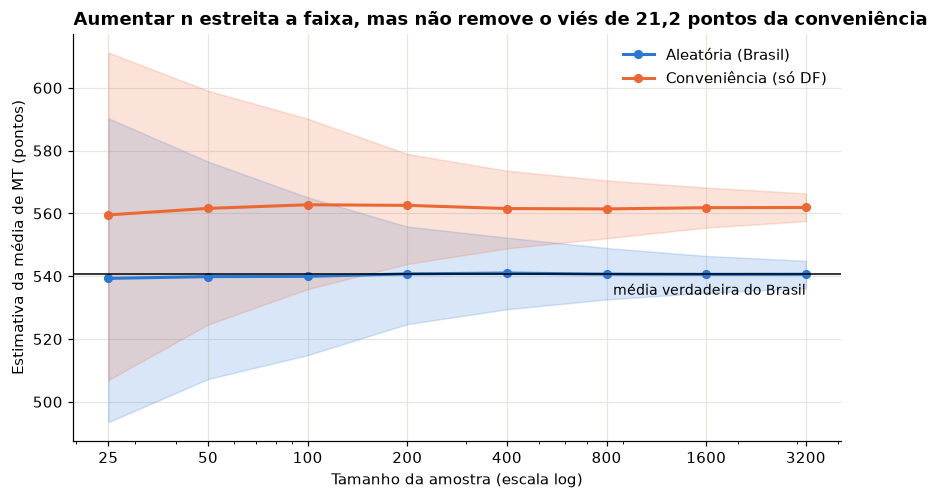

In [42]:
rng = np.random.default_rng(SEMENTE)                          # gerador desta seção
mt_df = base.loc[base.SG_UF_PROVA == 'DF', 'NU_NOTA_MT'].to_numpy()
tamanhos = np.array([25, 50, 100, 200, 400, 800, 1600, 3200])
estimativas = {'Aleatória (Brasil)': [], 'Conveniência (só DF)': []}
for n in tamanhos:
    estimativas['Aleatória (Brasil)'].append(rng.choice(mt, size=(500, n)).mean(axis=1))        # 500 amostras de cada tamanho
    estimativas['Conveniência (só DF)'].append(rng.choice(mt_df, size=(500, n)).mean(axis=1))

fig, ax = plt.subplots(figsize=(9, 4.8))
for (nome, est), cor in zip(estimativas.items(), (AZUL, LARANJA)):
    est = np.array(est)
    ax.fill_between(tamanhos, np.percentile(est, 2.5, axis=1), np.percentile(est, 97.5, axis=1), color=cor, alpha=0.18)
    ax.plot(tamanhos, est.mean(axis=1), 'o-', color=cor, lw=2, ms=5, label=nome)
ax.axhline(MU, color='black', lw=1)
ax.text(tamanhos[-1], MU - 3, 'média verdadeira do Brasil', ha='right', va='top', fontsize=9)
ax.set_xscale('log'); ax.set_xticks(tamanhos, [str(v) for v in tamanhos])
ax.set_xlabel('Tamanho da amostra (escala log)'); ax.set_ylabel('Estimativa da média de MT (pontos)')
ax.set_title(f'Aumentar n estreita a faixa, mas não remove o viés de {br(mt_df.mean() - MU)} pontos da conveniência')
ax.legend(loc='upper right')
plt.show()

**Viés de seleção: quem comparece (P1).** A base de notas só tem quem fez a prova. Se a chance de comparecer varia entre os grupos, as médias descrevem quem compareceu, e não quem se inscreveu. Esta análise usa **todos os inscritos**.

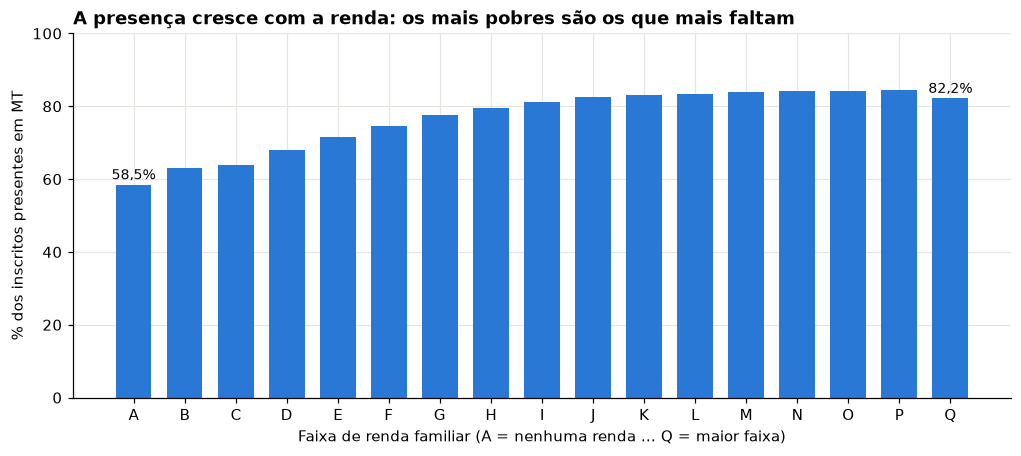

Presença por cor/raça:


,inscritos,% presentes em MT
TP_COR_RACA,,
Branca,1575848,73.6
Amarela,64512,66.6
Parda,1706798,65.8
Não declarado,52575,63.7
Preta,509511,62.5
Indígena,24711,58.8


Presença por sexo:


,inscritos,% presentes em MT
TP_SEXO,,
Feminino,2411185,68.5
Masculino,1522770,68.4


Presença por região:


,inscritos,% presentes em MT
SG_UF_PROVA,,
Nordeste,1423999,70.0
Sul,417688,69.3
Sudeste,1305362,68.8
Centro-Oeste,333452,66.2
Norte,453454,63.3


In [43]:
presente_mt = insc.TP_PRESENCA_MT == 1
pres_renda = 100 * presente_mt.groupby(insc.Q006).mean().loc[FAIXAS_RENDA]    # % de presentes em cada faixa de renda

fig, ax = plt.subplots(figsize=(11, 4.3))
ax.bar(pres_renda.index, pres_renda.values, color=AZUL, width=0.7)
for i in (0, 16):
    ax.text(i, pres_renda.iloc[i] + 1.5, f'{br(pres_renda.iloc[i])}%', ha='center', fontsize=9)
ax.set_ylim(0, 100)
ax.set_xlabel('Faixa de renda familiar (A = nenhuma renda ... Q = maior faixa)')
ax.set_ylabel('% dos inscritos presentes em MT')
ax.set_title('A presença cresce com a renda: os mais pobres são os que mais faltam')
plt.show()

for nome, grupos in (('cor/raça', insc.TP_COR_RACA.map(ROT_COR)), ('sexo', insc.TP_SEXO.map(ROT_SEXO)),
                     ('região', insc.SG_UF_PROVA.map(REGIAO))):
    tab = pd.DataFrame({'inscritos': grupos.value_counts(), '% presentes em MT': 100 * presente_mt.groupby(grupos).mean()})
    print(f'Presença por {nome}:'); display(tab.sort_values('% presentes em MT', ascending=False).round(1))

A diferença de presença por renda é grande o bastante para importar? O **qui-quadrado** testa se presença e renda são independentes, e o **V de Cramér** mede a força da associação (0 = nenhuma, 1 = total). O plano fixou V = 0,1 como mínimo relevante. (O qui-quadrado é explicado em detalhe na seção 7.5.)

In [44]:
tab_pres = pd.crosstab(insc.Q006.map(RENDA_4), presente_mt)                     # renda (4 faixas) × presente sim/não
qui2, p, gl, _ = stats.chi2_contingency(tab_pres)
V_PRES = stats.contingency.association(tab_pres.to_numpy(), method='cramer')
print(f'Presença × renda: χ² = {br(qui2, 0)}; g.l. = {gl}; p {fmt_p(p)}; V de Cramér = {br(V_PRES, 3)} (mínimo relevante: {br(V_MIN)})')

Presença × renda: χ² = 95.031; g.l. = 3; p < 0,001; V de Cramér = 0,155 (mínimo relevante: 0,1)


**Leitura:** a presença cresce com a renda e varia por cor/raça; entre os sexos é praticamente igual. As notas sub-representam justamente os grupos que mais faltam. É provável, mas não verificável (não temos a nota de quem faltou), que as diferenças entre inscritos sejam **maiores** que as medidas na base.

## 6.8 Cuidado com a composição: o paradoxo de Simpson

Os treineiros (quem fez a prova só para treinar) têm média de MT maior ou menor que os demais? Depende de como se olha (slide 73).

In [45]:
# Faixas etárias agrupadas a partir dos códigos do dicionário (1 = menos de 17 anos, 2 = 17, 3 = 18, 4 = 19, 5 = 20, ...)
faixa = pd.cut(base.TP_FAIXA_ETARIA, bins=[0, 2, 3, 5, 10, 20],
               labels=['1) até 17 anos', '2) 18 anos', '3) 19–20 anos', '4) 21–25 anos', '5) 26 anos ou mais']).rename('faixa etária')
grupo = base.IN_TREINEIRO.map({0: 'Demais', 1: 'Treineiros'}).rename('grupo')

simpson = base.groupby([faixa, grupo], observed=True).NU_NOTA_MT.mean().unstack()   # média por faixa e grupo
simpson.loc['TOTAL'] = base.groupby(grupo).NU_NOTA_MT.mean()
n_simpson = pd.crosstab(faixa, grupo, margins=True, margins_name='TOTAL')
simpson.round(1).join(n_simpson.rename(columns=lambda c: f'n {c}')).drop(columns='n TOTAL')

grupo,Demais,Treineiros,n Demais,n Treineiros
faixa etária,,,,
1) até 17 anos,556.3,552.4,407788,463293
2) 18 anos,540.7,493.6,637994,16896
3) 19–20 anos,540.0,471.1,439740,3641
4) 21–25 anos,537.8,432.7,318140,520
5) 26 anos ou mais,506.3,422.4,280527,651
TOTAL,538.5,549.4,2084189,485001


**Leitura:** no total, os treineiros têm média **maior**; em **cada** faixa etária, **menor**. Quase todos os treineiros estão na faixa mais nova, que é a de maior média: a composição etária inverte o sinal. Sempre que dois grupos têm composições diferentes, olhe também dentro dos estratos (como na seção 4.9).

---
# Etapa 7 — Testes de hipóteses: as diferenças são reais? E importam?

> *"Um teste de hipóteses responde a uma única pergunta: se não houvesse efeito nenhum, quão estranho seria o que eu observei? Não responde se o efeito é grande, importante ou causal."*

Vocabulário mínimo (slides 78–83):
- **H₀** (hipótese nula): não há diferença; **H₁**: há diferença.
- **Valor-p**: a chance de ver uma diferença pelo menos tão grande quanto a observada **se H₀ fosse verdadeira**. Se p < α (0,05), rejeita-se H₀.
- **Poder**: a chance de o teste detectar uma diferença do tamanho mínimo relevante, se ela existir.

Cada teste segue o mesmo roteiro de 8 passos: **(1)** pergunta e hipóteses; **(2)** margem de relevância; **(3)** tamanho da amostra pelo poder; **(4)** sorteio; **(5)** pressupostos; **(6)** o teste; **(7)** efeito, intervalo e leitura contra a margem; **(8)** relato com limitações.

## 7.1 Primeiro, a base inteira: tudo é "significativo"

Com milhões de linhas, qualquer diferença dá p < 0,001. O que distingue as comparações é o **tamanho do efeito** (slide 91).

,n A,n B,diferença (pontos),p,d de Cohen
comparação,,,,,
MT: renda > R$ 6.600 × renda ≤ R$ 1.320,377805,877472,168.476,0.0,1.576
MT: privada × pública,219207,783634,121.800,0.0,1.086
MT: brancos × pretos,1119070,301740,77.606,0.0,0.629
MT: brancos × pardos,1119070,1062833,62.954,0.0,0.517
MT: homens × mulheres,983373,1585817,46.543,0.0,0.379
Redação: mulheres × homens,1585817,983373,36.395,0.0,0.209
MT: municipal × estadual,5553,427787,16.282,0.0,0.151


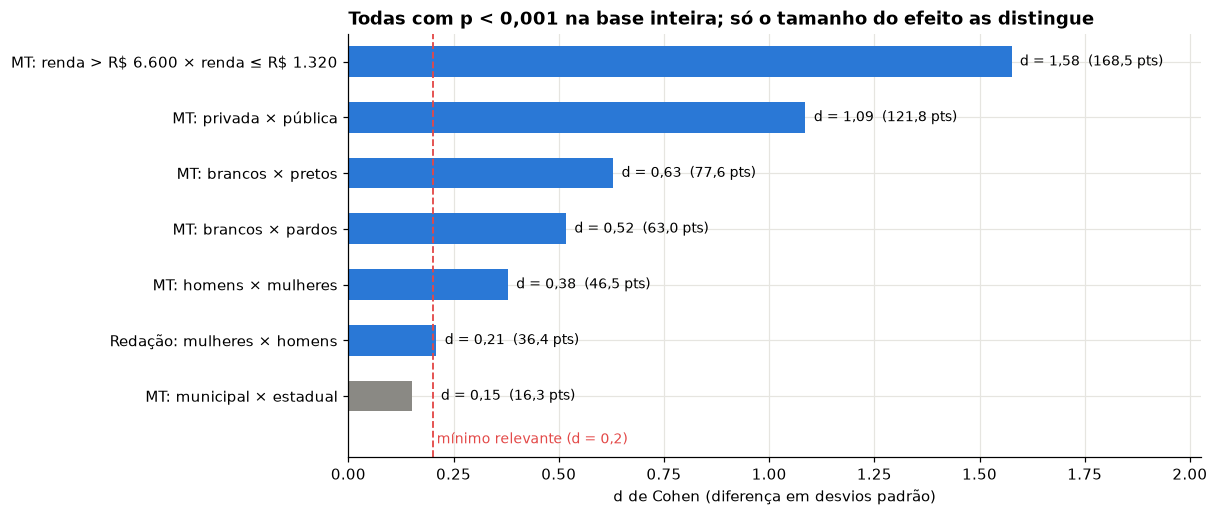

In [46]:
mt_dep = {c: base.loc[base.TP_DEPENDENCIA_ADM_ESC == c, 'NU_NOTA_MT'] for c in (1, 2, 3, 4)}   # MT por dependência
pares = [   # (nome da comparação, notas do grupo A, notas do grupo B)
    ('MT: renda > R$ 6.600 × renda ≤ R$ 1.320', base.loc[base.renda_4 == '4) acima de R$ 6.600', 'NU_NOTA_MT'], base.loc[base.renda_4 == '1) até R$ 1.320', 'NU_NOTA_MT']),
    ('MT: privada × pública', base.loc[base.TP_ESCOLA == 3, 'NU_NOTA_MT'], base.loc[base.TP_ESCOLA == 2, 'NU_NOTA_MT']),
    ('MT: brancos × pretos', base.loc[base.TP_COR_RACA == 1, 'NU_NOTA_MT'], base.loc[base.TP_COR_RACA == 2, 'NU_NOTA_MT']),
    ('MT: brancos × pardos', base.loc[base.TP_COR_RACA == 1, 'NU_NOTA_MT'], base.loc[base.TP_COR_RACA == 3, 'NU_NOTA_MT']),
    ('MT: homens × mulheres', base.loc[base.TP_SEXO == 'M', 'NU_NOTA_MT'], base.loc[base.TP_SEXO == 'F', 'NU_NOTA_MT']),
    ('Redação: mulheres × homens', base.loc[base.TP_SEXO == 'F', 'NU_NOTA_REDACAO'], base.loc[base.TP_SEXO == 'M', 'NU_NOTA_REDACAO']),
    ('MT: municipal × estadual', mt_dep[3], mt_dep[2]),
]
regua = pd.DataFrame([{'comparação': nome, 'n A': len(a), 'n B': len(b), 'diferença (pontos)': a.mean() - b.mean(),
                       'p': stats.ttest_ind(a, b, equal_var=False).pvalue, 'd de Cohen': d_cohen(a, b)}
                      for nome, a, b in pares]).set_index('comparação')
display(regua.round(3))

ordem = regua.sort_values('d de Cohen')
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(range(len(ordem)), ordem['d de Cohen'], color=[AZUL if d >= D_MIN else CINZA for d in ordem['d de Cohen']], height=0.55)
ax.set_yticks(range(len(ordem)), [c.replace('$', r'\$') for c in ordem.index])    # "\$": o $ não vira fórmula no gráfico
ax.axvline(D_MIN, color=VERMELHO, lw=1.2, ls='--')
ax.set_ylim(-1.1, len(ordem) - 0.5)
ax.text(D_MIN + 0.01, -0.85, f'mínimo relevante (d = {br(D_MIN)})', color=VERMELHO, fontsize=9)
for i, (d, dif) in enumerate(zip(ordem['d de Cohen'], ordem['diferença (pontos)'])):
    ax.text(max(d, D_MIN) + 0.02, i, f'd = {br(d, 2)}  ({br(dif)} pts)', va='center', fontsize=9)
ax.set_xlim(0, ordem['d de Cohen'].max() + 0.45)
ax.set_xlabel('d de Cohen (diferença em desvios padrão)')
ax.set_title('Todas com p < 0,001 na base inteira; só o tamanho do efeito as distingue')
plt.show()

## 7.2 Ex. 1 — Escolas públicas × privadas em Matemática (teste t de Welch)

O **teste t** compara as médias de **dois** grupos. A versão de **Welch** não exige que os dois grupos tenham a mesma variância, e por isso é a escolha padrão.

### Prompt para a IA — o Ex. 1 (teste t)

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: DataFrame base com a base de análise do ENEM 2023, tratada como população. Colunas: NU_NOTA_MT e TP_ESCOLA (2 pública, 3 privada; 1 = não respondeu, fora da análise). Dados observacionais, sem sorteio de quem estuda onde.

Pergunta: A nota média de MT difere entre públicas e privadas? H0: médias iguais; bilateral; α = 0,05; menor efeito relevante: d = 0,2.

Tarefa: (1) Converta d = 0,2 em pontos de MT e calcule o n por grupo para poder de 80% (TTestIndPower). (2) Sorteie n em cada grupo, sem reposição (semente 2023), e cheque os pressupostos. (3) t de Welch (ttest_ind com equal_var=False): diferença, IC95% e d de Cohen; classifique o IC contra a margem. (4) Controle negativo: embaralhe o grupo 1.000 vezes e conte quantos p < 0,05.

Restrições: Só código, sem resultados. Não use "poder observado". Não escreva "prova", "causa" nem "efeito da escola".

Formato: Suposições e como checá-las; código comentado; como ler cada saída, inclusive se p > 0,05.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- n por grupo = 394 (o mesmo para qualquer par com d = 0,2, poder de 80%, α = 0,05).
- Sorteados só entre TP_ESCOLA 2 ou 3, sem repetição.
- t refeito à mão: diferença ÷ √(s₁²/n₁ + s₂²/n₂).
- Controle negativo: cerca de 5% de p < 0,05 com os rótulos embaralhados.
- O IC da amostra contém a diferença verdadeira da população?

*Slides v11: 87–92.*

**Passo 1 — Pergunta e hipóteses.** H₀: média(privada) = média(pública); H₁: são diferentes; α = 0,05, bilateral. População: concluintes de 2023 da base de análise que informaram o tipo de escola.

**Passo 2 — Margem de relevância.** d = 0,2, convertido em pontos de MT com o desvio padrão dos dois grupos.

**Passo 3 — Tamanho da amostra.** `TTestIndPower().solve_power` resolve a equação do poder: quantos por grupo para ter 80% de chance de detectar d = 0,2?

In [47]:
pop_pub = base.loc[base.TP_ESCOLA == 2, 'NU_NOTA_MT'].to_numpy()       # "população" de públicas
pop_priv = base.loc[base.TP_ESCOLA == 3, 'NU_NOTA_MT'].to_numpy()      # "população" de privadas

dp_dois_grupos = np.sqrt((pop_pub.var(ddof=1) + pop_priv.var(ddof=1)) / 2)
MARGEM_EX1 = D_MIN * dp_dois_grupos                                    # d = 0,2 em pontos de MT
n_ex1 = int(np.ceil(TTestIndPower().solve_power(effect_size=D_MIN, alpha=ALFA, power=PODER)))
print(f'Margem de relevância: d = 0,2 equivale a ±{br(MARGEM_EX1)} pontos de MT')
print(f'n por grupo para poder de 80%: {n_ex1}')

Margem de relevância: d = 0,2 equivale a ±23,1 pontos de MT
n por grupo para poder de 80%: 394


**Passo 4 — Sorteio.** Sorteia-se **separado em cada grupo** (amostra estratificada): os dois grupos ficam com o n planejado, mesmo a privada sendo bem menor.

**Passo 5 — Pressupostos.** (a) Independência: sorteio, cada participante uma vez. (b) Média aproximadamente normal: com n = 394, o TCL garante (seção 5.4), mesmo com alguma assimetria. (c) Variâncias: o Welch não exige que sejam iguais.

In [48]:
rng = np.random.default_rng(SEMENTE)                                   # gerador desta seção
a_pub = rng.choice(pop_pub, n_ex1, replace=False)
a_priv = rng.choice(pop_priv, n_ex1, replace=False)
print(f'Pública: média {br(a_pub.mean())}, dp {br(a_pub.std(ddof=1))}, assimetria {br(stats.skew(a_pub), 2)}')
print(f'Privada: média {br(a_priv.mean())}, dp {br(a_priv.std(ddof=1))}, assimetria {br(stats.skew(a_priv), 2)}')
print(f'Maior variância ÷ menor = {br(max(a_pub.var(ddof=1), a_priv.var(ddof=1)) / min(a_pub.var(ddof=1), a_priv.var(ddof=1)), 2)}')

Pública: média 501,2, dp 110,1, assimetria 0,56
Privada: média 636,0, dp 124,1, assimetria -0,34
Maior variância ÷ menor = 1,27


**Passos 6 e 7 — O teste, o efeito e a leitura.** O IC95% da diferença é lido contra a margem de relevância. São cinco leituras possíveis; a função `classificar` escreve a regra uma vez só:
- IC **inteiro além** da margem → **diferença relevante**;
- IC **inteiro dentro** da margem → **equivalente na prática** (ou diferente, mas irrelevante, se não incluir o zero);
- IC que não inclui o zero, mas cruza a margem → **diferente; relevância incerta**;
- IC que inclui o zero e cruza a margem → **inconclusivo** (p > 0,05 **não** prova igualdade).

In [49]:
def classificar(inf, sup, margem):
    # inf e sup: limites do IC95% da diferença; margem: menor diferença relevante (em pontos)
    if inf > margem or sup < -margem:
        return 'diferença relevante'
    if -margem < inf and sup < margem:
        return 'diferente, mas irrelevante' if (inf > 0 or sup < 0) else 'equivalente na prática'
    if inf > 0 or sup < 0:
        return 'diferente; relevância incerta'
    return 'inconclusivo'

teste = stats.ttest_ind(a_priv, a_pub, equal_var=False)                # t de Welch
ic = teste.confidence_interval(0.95)                                   # IC95% da diferença de médias
dif = a_priv.mean() - a_pub.mean()
print(f'Privadas − públicas: {br(dif)} pontos; IC95% [{br(ic.low)}; {br(ic.high)}]; t = {br(teste.statistic, 2)}; '
      f'p {fmt_p(teste.pvalue)}; d = {br(d_cohen(a_priv, a_pub), 2)}')
print(f'Leitura contra a margem de ±{br(MARGEM_EX1)} pontos: {classificar(ic.low, ic.high, MARGEM_EX1)}')

Privadas − públicas: 134,8 pontos; IC95% [118,4; 151,2]; t = 16,13; p < 0,001; d = 1,15
Leitura contra a margem de ±23,1 pontos: diferença relevante


In [50]:
# Verificação independente 1: o t refeito à mão
ep_dif = np.sqrt(a_priv.var(ddof=1) / n_ex1 + a_pub.var(ddof=1) / n_ex1)   # erro padrão da diferença
print(f't à mão = {br(dif, 2)} ÷ {br(ep_dif, 2)} = {br(dif / ep_dif, 2)} (scipy: {br(teste.statistic, 2)})')

# Verificação independente 2: o valor verdadeiro (que, na vida real, não teríamos)
dif_pop = pop_priv.mean() - pop_pub.mean()
print(f'Diferença verdadeira na população = {br(dif_pop)} pontos; está no IC da amostra? {ic.low <= dif_pop <= ic.high}')

# Verificação independente 3: controle negativo. Embaralhando os rótulos "pública/privada", não há diferença real;
# o teste deve dar p < 0,05 em cerca de 5% das vezes (a taxa de falso positivo prometida por α)
rng = np.random.default_rng(SEMENTE)                                   # gerador desta seção
todas = np.concatenate([a_priv, a_pub])
falsos = 0
for _ in range(1000):
    rotulo = rng.permutation(len(todas)) < n_ex1                       # metade sorteada como "privada"
    falsos += stats.ttest_ind(todas[rotulo], todas[~rotulo], equal_var=False).pvalue < 0.05
print(f'Controle negativo: {br(100 * falsos / 1000)}% de p < 0,05 com rótulos embaralhados (esperado ≈ 5%)')

t à mão = 134,77 ÷ 8,36 = 16,13 (scipy: 16,13)
Diferença verdadeira na população = 121,8 pontos; está no IC da amostra? True


Controle negativo: 4,4% de p < 0,05 com rótulos embaralhados (esperado ≈ 5%)


**Passo 8 — Relato.** Na amostra planejada, a média de MT das privadas fica bem acima da das públicas, com o IC95% **inteiro acima** da margem de relevância, e o d de Cohen é grande. *Limitações:* compara só concluintes de 2023 que informaram a escola; é observacional: a diferença mistura renda, capital cultural e seleção de alunos (seção 4.9). Não é "o efeito da escola privada".

## 7.3 O valor-p cai com n; o efeito não

Municipal × estadual em MT tem d ≈ 0,15, **abaixo** do relevante. O que acontece quando o mesmo par é testado com amostras cada vez maiores? (slide 90)

,p mediano,"% com p < 0,05",d médio
n por grupo,,,
10,0.460,3.75,0.147
20,0.435,7.50,0.157
50,0.360,13.00,0.147
100,0.274,17.00,0.149
200,0.154,29.50,0.144
500,0.022,64.50,0.146
1000,0.001,90.25,0.149
2000,0.000,99.75,0.145
5000,0.000,100.00,0.145


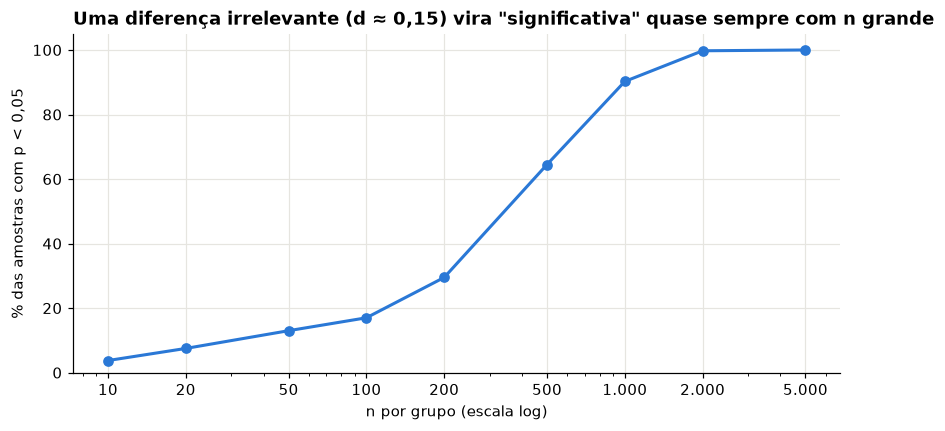

In [51]:
rng = np.random.default_rng(SEMENTE)                                   # gerador desta seção
mun, est = mt_dep[3].to_numpy(), mt_dep[2].to_numpy()
tamanhos = np.array([10, 20, 50, 100, 200, 500, 1000, 2000, 5000])
linhas = []
for n in tamanhos:
    A, B = rng.choice(mun, size=(400, n)), rng.choice(est, size=(400, n))       # 400 pares de amostras de tamanho n
    p = stats.ttest_ind(A, B, axis=1, equal_var=False).pvalue                    # um teste t por par
    d = (A.mean(axis=1) - B.mean(axis=1)) / np.sqrt((A.var(axis=1, ddof=1) + B.var(axis=1, ddof=1)) / 2)
    linhas.append({'n por grupo': n, 'p mediano': np.median(p), '% com p < 0,05': 100 * (p < 0.05).mean(), 'd médio': d.mean()})
valor_p_n = pd.DataFrame(linhas).set_index('n por grupo')
display(valor_p_n.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(valor_p_n.index, valor_p_n['% com p < 0,05'], 'o-', color=AZUL, lw=2)
ax.set_xscale('log'); ax.set_xticks(tamanhos, [br(v, 0) for v in tamanhos])
ax.set_ylim(0, 105)
ax.set_xlabel('n por grupo (escala log)'); ax.set_ylabel('% das amostras com p < 0,05')
ax.set_title('Uma diferença irrelevante (d ≈ 0,15) vira "significativa" quase sempre com n grande')
plt.show()

**Três lições:** (1) com n pequeno, uma diferença real dá "não significativo" na maioria das amostras: **p > 0,05 não prova igualdade**; (2) com n grande, tudo fica significativo, inclusive uma diferença abaixo do relevante: **significativo e irrelevante**; (3) o d estimado fica no mesmo lugar em qualquer n. Quem decide é o **tamanho do efeito**, lido contra a margem.

## 7.4 Ex. 2 — As quatro dependências administrativas (ANOVA + Tukey)

A **ANOVA** (análise de variância) compara **mais de dois grupos** de uma vez. A ideia: se as médias dos grupos fossem iguais, a variação **entre** os grupos seria parecida com a variação **dentro** deles. A razão entre as duas é a estatística **F**; F muito maior que 1 indica que pelo menos uma média difere. Se a ANOVA rejeitar H₀, o pós-teste de **Tukey** diz **quais pares** diferem.

### Prompt para a IA — o Ex. 2 (ANOVA e Tukey)

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: DataFrame base com a base de análise do ENEM 2023, tratada como população. Colunas: NU_NOTA_MT e TP_DEPENDENCIA_ADM_ESC (1 federal, 2 estadual, 3 municipal, 4 privada; vazia para quem não informou). Vou sortear o mesmo número de participantes em cada dependência, com semente 2023.

Pergunta: A média de MT difere entre as quatro dependências? H0: as quatro médias são iguais; α = 0,05; menor efeito relevante: d = 0,2 entre duas dependências.

Tarefa: (1) Converta d = 0,2 em pontos (DP dentro dos grupos) e calcule o n por grupo com α = 0,05/6 (6 pares; TTestIndPower). (2) Sorteie esse n em cada grupo e cheque as suposições. (3) ANOVA (f_oneway) com a tabela completa: somas de quadrados, g.l., variâncias estimadas, razão F, valor-p e η². (4) Tukey (pairwise_tukeyhsd) com o IC95% de cada par, classificado contra a margem.

Restrições: Não chame de "equivalentes" os pares com p ≥ 0,05. Não calcule de cabeça. Comente em português.

Formato: Tabela ANOVA; tabela de pares com a leitura de cada um; três frases para a diretoria.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- Os 4 grupos têm o mesmo n e só códigos 1 a 4.
- F refeito à mão: (SQ entre ÷ g.l. entre) ÷ (SQ dentro ÷ g.l. dentro).
- Razão entre a maior e a menor variância abaixo de 4 (regra prática).
- Pares com p ajustado ≥ 0,05 lidos como inconclusivos, salvo se o IC couber inteiro na margem.
- Comparar o η² da amostra com o da população.

*Slides v11: 93–98.*

**Passo 1 — Hipóteses.** H₀: as quatro médias são iguais; H₁: pelo menos uma difere; α = 0,05. População: quem tem a dependência informada (subconjunto não aleatório; seção 2.3).

**Passos 2 e 3 — Margem e tamanho da amostra.** d = 0,2, convertido em pontos com o desvio padrão **dentro** dos grupos. O Tukey compara 6 pares; para não multiplicar os falsos positivos, o planejamento usa α ÷ 6 em cada par (correção de **Bonferroni**), o que pede amostras maiores.

In [52]:
pop_dep = base.loc[base.TP_DEPENDENCIA_ADM_ESC.notna(), ['TP_DEPENDENCIA_ADM_ESC', 'NU_NOTA_MT']].copy()
pop_dep['dependência'] = pop_dep.TP_DEPENDENCIA_ADM_ESC.astype(int).map(ROT_DEPENDENCIA)

# Desvio padrão DENTRO dos grupos: junta as variâncias dos 4 grupos, ponderadas pelo tamanho de cada um
g = pop_dep.groupby('dependência').NU_NOTA_MT.agg(['count', 'var'])
dp_dentro = np.sqrt(((g['count'] - 1) * g['var']).sum() / (g['count'].sum() - 4))
MARGEM_EX2 = D_MIN * dp_dentro
n_ex2 = int(np.ceil(TTestIndPower().solve_power(effect_size=D_MIN, alpha=ALFA / 6, power=PODER)))
print(f'd = 0,2 equivale a ±{br(MARGEM_EX2)} pontos | α por par = 0,05 ÷ 6 = {br(ALFA / 6, 4)} | n por grupo = {n_ex2} (sem a correção: {n_ex1})')

d = 0,2 equivale a ±22,5 pontos | α por par = 0,05 ÷ 6 = 0,0083 | n por grupo = 608 (sem a correção: 394)


**Por que corrigir o α: quem procura, acha.** Sem diferença nenhuma, cada teste a 5% tem 1 chance em 20 de dar "significativo". Com muitas comparações, algum falso positivo aparece quase sempre. Demonstração: 100 testes entre duas metades **sorteadas** da mesma população.

In [53]:
rng = np.random.default_rng(SEMENTE)                                   # gerador desta seção
ps = []
for _ in range(100):
    idx = rng.choice(len(mt), 1000, replace=False)                     # 1.000 participantes sorteados...
    ps.append(stats.ttest_ind(mt[idx[:500]], mt[idx[500:]], equal_var=False).pvalue)   # ...divididos em duas metades
ps = np.array(ps)
print(f'p < 0,05 em {(ps < 0.05).sum()} de 100 testes, sem diferença real nenhuma | com Bonferroni (α ÷ 100): {(ps < 0.05 / 100).sum()}')

p < 0,05 em 5 de 100 testes, sem diferença real nenhuma | com Bonferroni (α ÷ 100): 0


**Passos 4 e 5 — Sorteio e pressupostos.** O mesmo n em cada dependência. Pressupostos: independência (sorteio), média aproximadamente normal (TCL) e variâncias parecidas (regra prática: a maior até 4 vezes a menor; o teste de Levene é uma conferência formal).

In [54]:
amostra_dep = pop_dep.groupby('dependência', group_keys=False).sample(n_ex2, random_state=SEMENTE)   # n_ex2 de cada grupo
display(amostra_dep.groupby('dependência').NU_NOTA_MT.agg(n='count', média='mean', dp='std').loc[DEPS].round(1))
variancias = amostra_dep.groupby('dependência').NU_NOTA_MT.var()
grupos_notas = [g.to_numpy() for _, g in amostra_dep.groupby('dependência').NU_NOTA_MT]      # lista com as notas de cada grupo
print(f'Maior variância ÷ menor = {br(variancias.max() / variancias.min(), 2)} (regra prática: até 4) | Levene: p {fmt_p(stats.levene(*grupos_notas).pvalue)}')

,n,média,dp
dependência,,,
Federal,608,604.1,120.9
Estadual,608,514.5,110.9
Municipal,608,524.9,115.5
Privada,608,628.5,121.1


Maior variância ÷ menor = 1,19 (regra prática: até 4) | Levene: p 0,150


**Passo 6 — A ANOVA, com a tabela completa.** SQ = soma de quadrados (variação); g.l. = graus de liberdade; a "variância estimada" é SQ ÷ g.l.; F = variância entre ÷ variância dentro. η² = SQ entre ÷ SQ total (seção 4.10).

In [55]:
y, grupos = amostra_dep.NU_NOTA_MT, amostra_dep['dependência']
k, N = 4, len(y)                                                       # 4 grupos, N participantes
medias = y.groupby(grupos).agg(['count', 'mean'])
sq_entre = (medias['count'] * (medias['mean'] - y.mean()) ** 2).sum() # variação das médias dos grupos em torno da geral
sq_total = ((y - y.mean()) ** 2).sum()                                 # variação de cada nota em torno da geral
sq_dentro = sq_total - sq_entre                                        # o que sobra: variação dentro dos grupos
F = (sq_entre / (k - 1)) / (sq_dentro / (N - k))
display(pd.DataFrame({'soma de quadrados': [sq_entre, sq_dentro, sq_total], 'g.l.': [k - 1, N - k, N - 1],
                      'variância estimada': [sq_entre / (k - 1), sq_dentro / (N - k), np.nan], 'F': [F, np.nan, np.nan]},
                     index=['entre grupos', 'dentro dos grupos', 'total']).round(2))
anova = stats.f_oneway(*grupos_notas)                                  # a mesma ANOVA pela biblioteca, para conferir
print(f'F = {br(F, 2)} (scipy: {br(anova.statistic, 2)}); p {fmt_p(anova.pvalue)} | η² = {br(sq_entre / sq_total, 3)} na amostra; '
      f'{br(eta2(pop_dep.NU_NOTA_MT, pop_dep["dependência"]), 3)} na população')

,soma de quadrados,g.l.,variância estimada,F
entre grupos,5884732.55,3,1961577.52,142.82
dentro dos grupos,33348371.45,2428,13734.91,NaN
total,39233104.00,2431,NaN,NaN


F = 142,82 (scipy: 142,82); p < 0,001 | η² = 0,150 na amostra; 0,210 na população


**Passo 7 — Quais pares diferem, e se importam: Tukey com a margem.** Para cada par, o Tukey dá a diferença, o IC95% (já ajustado para as 6 comparações) e o p ajustado. Cada IC é lido contra a margem com a função `classificar` da seção 7.2.

,meandiff,lower,upper,p-adj,leitura (IC × margem)
par,,,,,
Estadual × Federal,89.55,72.27,106.83,0.00,diferença relevante
Estadual × Municipal,10.37,-6.91,27.65,0.41,inconclusivo
Estadual × Privada,113.97,96.69,131.25,0.00,diferença relevante
Federal × Municipal,-79.18,-96.46,-61.90,0.00,diferença relevante
Federal × Privada,24.42,7.14,41.70,0.00,diferente; relevância incerta
Municipal × Privada,103.60,86.32,120.88,0.00,diferença relevante


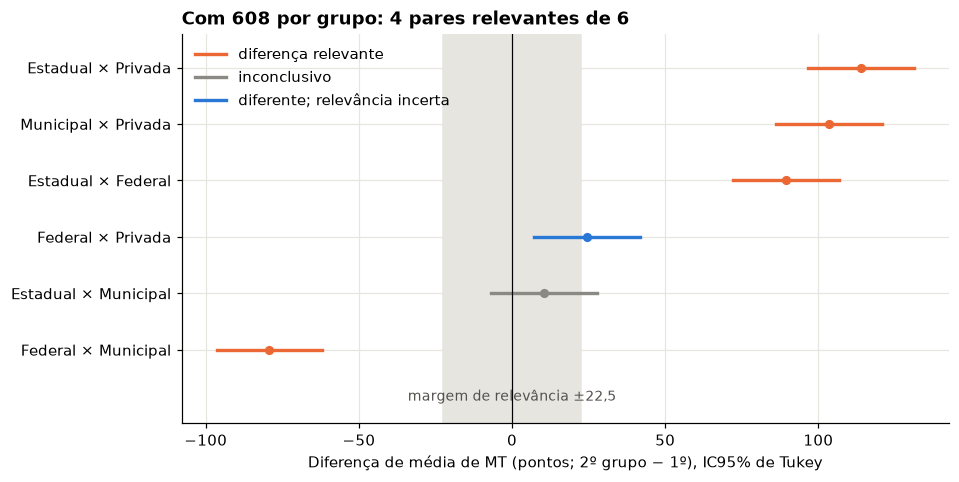

In [56]:
tk = pairwise_tukeyhsd(amostra_dep.NU_NOTA_MT, amostra_dep['dependência'], alpha=ALFA)
tukey = pd.DataFrame(tk.summary().data[1:], columns=tk.summary().data[0])       # a tabela do Tukey como DataFrame
tukey['par'] = tukey.group1 + ' × ' + tukey.group2
tukey['leitura (IC × margem)'] = [classificar(i, s, MARGEM_EX2) for i, s in zip(tukey.lower, tukey.upper)]
display(tukey.set_index('par')[['meandiff', 'lower', 'upper', 'p-adj', 'leitura (IC × margem)']].round(2))

fig, ax = plt.subplots(figsize=(9, 4.6))
t = tukey.sort_values('meandiff').reset_index(drop=True)
ax.axvspan(-MARGEM_EX2, MARGEM_EX2, color='#e6e5e0', zorder=0)           # faixa cinza: dentro da margem = irrelevante
ax.text(0, -0.9, f'margem de relevância ±{br(MARGEM_EX2)}', ha='center', fontsize=9, color='#52514e')
cores = {'diferença relevante': LARANJA, 'inconclusivo': CINZA, 'equivalente na prática': VERDE,
         'diferente, mas irrelevante': VERDE, 'diferente; relevância incerta': AZUL}
for i, r in t.iterrows():
    ax.plot([r.lower, r.upper], [i, i], color=cores[r['leitura (IC × margem)']], lw=2.2)
    ax.plot(r.meandiff, i, 'o', color=cores[r['leitura (IC × margem)']], ms=5)
ax.axvline(0, color='black', lw=0.8)
ax.set_ylim(-1.3, len(t) - 0.4)
ax.set_yticks(range(len(t)), t.par)
ax.set_xlabel('Diferença de média de MT (pontos; 2º grupo − 1º), IC95% de Tukey')
ax.legend(handles=[plt.Line2D([], [], color=cores[l], lw=2.2, label=l) for l in cores if l in set(t['leitura (IC × margem)'])], loc='upper left')
ax.set_title(f"Com {n_ex2} por grupo: {(t['leitura (IC × margem)'] == 'diferença relevante').sum()} pares relevantes de 6")
plt.show()

**Passo 8 — Relato.** A ANOVA rejeita H₀ com folga, e a dependência acompanha uma parte considerável da variação de MT (η² de 0,15 na amostra e 0,21 na população); ainda assim, a maior parte da variação está **dentro** de cada tipo de escola. Federais e privadas ficam bem acima de estaduais e municipais (4 pares relevantes). Federal × privada: diferente, mas com relevância incerta. Estadual × municipal: **inconclusivo**, e não "iguais". *Limitações:* subconjunto não aleatório dos concluintes; observacional: a diferença mistura o perfil dos alunos de cada rede com a escola.

## 7.5 Ex. 3 — Escolaridade do pai × renda familiar (qui-quadrado)

Duas variáveis **categóricas**, por isso o teste é outro. O **qui-quadrado** compara a tabela observada com a tabela **esperada** se não houvesse associação nenhuma (cada casela esperada = total da linha × total da coluna ÷ total geral). Quanto mais as duas tabelas diferem, maior o χ². A força da associação é medida pelo **V de Cramér**. Usa **todos os inscritos** (escolaridade do pai e renda não dependem da presença na prova), sem quem respondeu "Não sei" sobre o pai.

### Prompt para a IA — o Ex. 3 (qui-quadrado)

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: DataFrame insc com todos os inscritos do ENEM 2023. Q001 = escolaridade do pai (A a G; H = "Não sei"); Q006 = renda familiar em 17 faixas (A a Q).

Pergunta: A escolaridade do pai e a renda familiar estão associadas? H0: independência; α = 0,05; menor efeito relevante: V de Cramér = 0,1.

Tarefa: (1) Exclua "Não sei"; agrupe Q001 em 5 níveis (A–C fund. incompleto; D fund.; E médio; F superior; G pós) e Q006 em 4 faixas (A–B; C–E; F–H; I–Q). (2) Qui-quadrado (scipy.stats.chi2_contingency): χ², g.l., valor-p e menor esperada; V de Cramér; % por linha num mapa de calor. (3) Planeje a amostra: n para V = 0,1 com poder de 80% (GofChisquarePower, w = V × √3, 12 g.l.) e n para esperadas ≥ 5; use o maior. (4) Repita o teste nessa amostra (semente 2023); se alguma esperada ficar < 5, dê também o p por permutação.

Restrições: Confira que todas as frequências esperadas são ≥ 5. Nada de linguagem causal. Só código.

Formato: Tabelas; mapa de calor; como ler χ², valor-p e V na população e na amostra.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- g.l. = (5 − 1) × (4 − 1) = 12.
- Uma esperada refeita à mão: total da linha × total da coluna ÷ total geral.
- O V quase não muda entre população e amostra; o χ² cai muito.
- Usar o V como se fosse o w daria um n bem maior (erro comum).

*Slides v11: 99–103.*

População (n = 3.530.429): χ² = 1.199.953; g.l. = 12; p < 0,001; menor esperada = 32.708; V = 0,337
Esperada (5) Pós-graduação; 1) até R$ 1.320) à mão = 94.433,4 | scipy = 94.433,4


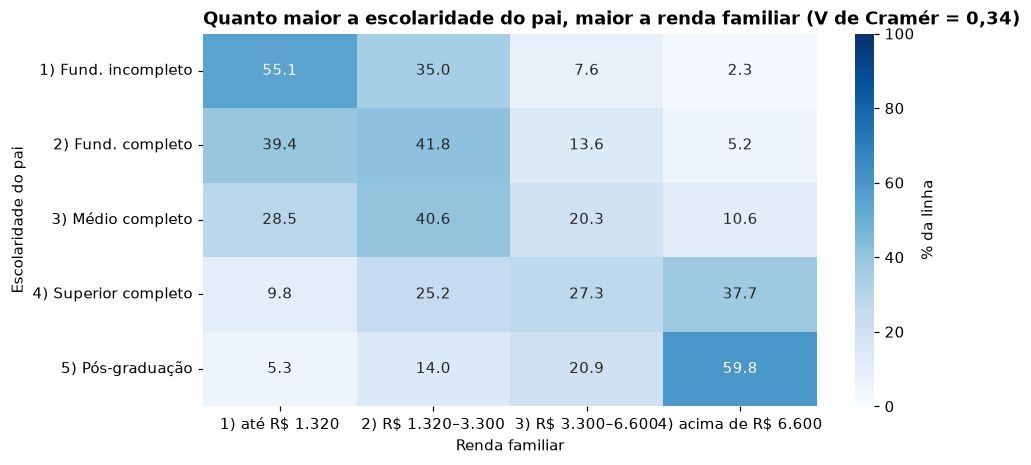

In [57]:
# Passo 1: H0 = escolaridade do pai e renda são independentes. Primeiro, a "verdade" na população
pai = insc.loc[insc.Q001 != 'H', ['Q001', 'Q006']].copy()            # sem "Não sei"
pai['instr_pai'] = pai.Q001.map(INSTR_5)
pai['renda'] = pai.Q006.map(RENDA_4)
tab = pd.crosstab(pai.instr_pai, pai.renda)
qui2, p, gl, esperado = stats.chi2_contingency(tab)                  # esperado: a tabela se não houvesse associação
V_POP = stats.contingency.association(tab.to_numpy(), method='cramer')
print(f'População (n = {br(len(pai), 0)}): χ² = {br(qui2, 0)}; g.l. = {gl}; p {fmt_p(p)}; menor esperada = {br(esperado.min(), 0)}; V = {br(V_POP, 3)}')

# Verificação independente: uma casela esperada à mão
lin, col = '5) Pós-graduação', '1) até R$ 1.320'
print(f'Esperada ({lin}; {col}) à mão = {br(tab.loc[lin].sum() * tab[col].sum() / tab.to_numpy().sum(), 1)} | '
      f'scipy = {br(esperado[tab.index.get_loc(lin), tab.columns.get_loc(col)], 1)}')

pct = pd.crosstab(pai.instr_pai, pai.renda, normalize='index') * 100   # % de cada linha
fig, ax = plt.subplots(figsize=(9, 4.4))
sns.heatmap(pct, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=100, cbar_kws={'label': '% da linha'}, ax=ax)
ax.set_xlabel('Renda familiar'); ax.set_ylabel('Escolaridade do pai'); ax.tick_params(axis='x', rotation=0)
ax.set_title(f'Quanto maior a escolaridade do pai, maior a renda familiar (V de Cramér = {br(V_POP, 2)})')
plt.show()

**Passos 2 e 3 — Margem e tamanho da amostra.** Mínimo relevante: V = 0,1. A função de poder (`GofChisquarePower`) não recebe o V, e sim o **w de Cohen**, ligado a ele por w = V × √(menor dimensão da tabela − 1). Na tabela 5 × 4, w = 0,1 × √3 ≈ 0,17. O qui-quadrado também pede **esperadas ≥ 5** em todas as caselas; usa-se o maior dos dois n.

In [58]:
W_MIN = V_MIN * np.sqrt(min(tab.shape) - 1)                          # converte o V mínimo em w de Cohen
n_poder = int(np.ceil(GofChisquarePower().solve_power(effect_size=W_MIN, n_bins=gl + 1, alpha=ALFA, power=PODER)))
p_casela_rara = np.outer(tab.sum(axis=1), tab.sum(axis=0)).min() / tab.to_numpy().sum() ** 2   # proporção esperada da casela mais rara
n_esperadas = int(np.ceil(5 / p_casela_rara))                        # n para essa casela ter esperada ≥ 5
n_ex3 = max(n_poder, n_esperadas)
print(f'w = {br(W_MIN, 3)} | n pelo poder = {n_poder} | n para esperadas ≥ 5 = {n_esperadas} | n planejado = {n_ex3}')
print(f'Erro comum: usar o V como se fosse o w daria n = {br(np.ceil(GofChisquarePower().solve_power(effect_size=V_MIN, n_bins=gl + 1, alpha=ALFA, power=PODER)), 0)}')

w = 0,173 | n pelo poder = 578 | n para esperadas ≥ 5 = 540 | n planejado = 578
Erro comum: usar o V como se fosse o w daria n = 1.734


**Passos 4 a 7 — Sorteio, pressuposto, teste e V.** Se alguma esperada ficar abaixo de 5 na amostra, o valor-p também é calculado por **permutação**: embaralha-se a renda muitas vezes (o que destrói qualquer associação) e conta-se em quantas o χ² embaralhado é pelo menos tão grande quanto o observado. Esse caminho não depende da regra das esperadas.

In [59]:
sub = pai.sample(n_ex3, random_state=SEMENTE)                         # amostra aleatória simples de n_ex3 inscritos
tab_s = pd.crosstab(sub.instr_pai, sub.renda)
qui2_s, p_s, gl_s, esp_s = stats.chi2_contingency(tab_s)
V_EX3 = stats.contingency.association(tab_s.to_numpy(), method='cramer')
print(f'Amostra (n = {n_ex3}): χ² = {br(qui2_s, 1)}; g.l. = {gl_s}; p {fmt_p(p_s)}; V = {br(V_EX3, 3)}; '
      f'caselas com esperada < 5: {(esp_s < 5).sum()} de {esp_s.size}')
display(tab_s)

if (esp_s < 5).any():
    rng = np.random.default_rng(SEMENTE)                              # gerador desta seção
    renda_s = sub.renda.to_numpy()
    qui2_embaralhados = np.array([stats.chi2_contingency(pd.crosstab(sub.instr_pai.to_numpy(), rng.permutation(renda_s)))[0]
                                  for _ in range(2000)])
    print(f'p por permutação (2.000 embaralhamentos) = {br((1 + (qui2_embaralhados >= qui2_s).sum()) / 2001, 4)}')

Amostra (n = 578): χ² = 178,0; g.l. = 12; p < 0,001; V = 0,320; caselas com esperada < 5: 2 de 20


renda,1) até R$ 1.320,2) R$ 1.320–3.300,3) R$ 3.300–6.600,4) acima de R$ 6.600
instr_pai,,,,
1) Fund. incompleto,138,83,17,6
2) Fund. completo,23,29,16,6
3) Médio completo,54,73,33,16
4) Superior completo,3,12,11,16
5) Pós-graduação,3,8,9,22


p por permutação (2.000 embaralhamentos) = 0,0005


**Passo 8 — Relato.** A associação entre escolaridade do pai e renda familiar é **moderada** (V bem acima do mínimo de 0,1), na população e na amostra planejada. O χ² cai muito da população para a amostra porque **cresce com n**; o V quase não muda: é ele que mede a **força**. *Limitações:* respostas autodeclaradas; "Não sei" excluído (cerca de 10% dos inscritos); associação, não causa.

---
# Etapa 8 — Correlação e regressão: o que permanece quando controlamos os outros fatores (P6)

> *"Correlação resume a força de uma relação linear; regressão transforma essa relação numa equação. Nenhuma das duas, sozinha, prova causa."*

## 8.1 Correlação entre as notas

O **r de Pearson** vai de −1 a 1: perto de 1, quando uma nota sobe a outra também sobe, quase em linha reta; perto de 0, não há relação linear. O **ρ de Spearman** usa as posições (ranking) em vez dos valores, e por isso serve também para variáveis ordinais, como as faixas de renda.

### Prompt para a IA — a correlação

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico que mede relações entre variáveis quantitativas.

Contexto: DataFrame base com a base de análise do ENEM 2023 e as cinco notas (NU_NOTA_CN, NU_NOTA_CH, NU_NOTA_LC, NU_NOTA_MT, NU_NOTA_REDACAO).

Pergunta: Quão fortemente as notas andam juntas? E quanto o r de uma amostra pequena pode se afastar do r verdadeiro?

Tarefa: (1) Matriz de correlação de Pearson das cinco notas, num mapa de calor. (2) Spearman de CN × MT. (3) Para n = 10, 30, 100 e 1.000, sorteie 1.000 amostras (semente 2023), calcule o r de CN × MT em cada uma e mostre o intervalo onde caem 95% dos r.

Restrições: Não interprete correlação como causa. Vetorize o cálculo do r. Só código.

Formato: Código comentado; depois, uma frase sobre o que um r = 0,7 com n = 10 permite afirmar.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- Diagonal da matriz = 1 e matriz simétrica.
- O r calculado de outro jeito bate com `np.corrcoef` numa amostra.
- Com n = 10, o intervalo de 95% dos r é muito largo.

*Slides v11: 109–113.*

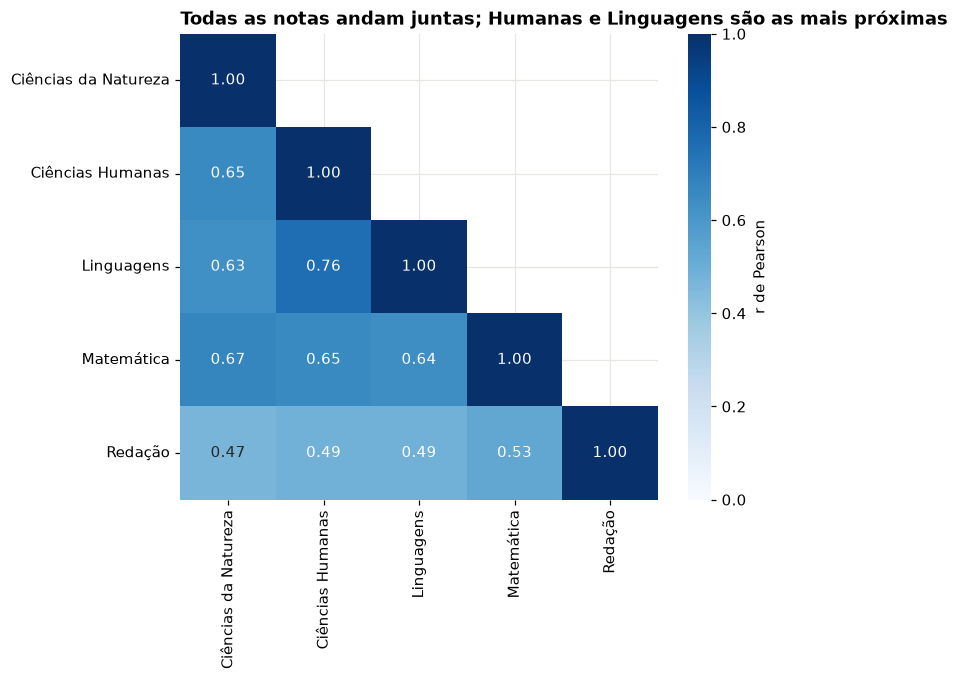

CN × MT: r de Pearson = 0,674


MT × faixa de renda (ordinal): ρ de Spearman = 0,460


In [60]:
corr = base[NOTAS].rename(columns=NOME_NOTA).corr()                   # matriz de correlações de Pearson
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)                # esconde a metade de cima (repetida)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', mask=mascara, vmin=0, vmax=1, ax=ax, cbar_kws={'label': 'r de Pearson'})
ax.set_title('Todas as notas andam juntas; Humanas e Linguagens são as mais próximas')
plt.show()

cn = base.NU_NOTA_CN.to_numpy()
r_cn_mt = np.corrcoef(cn, mt)[0, 1]
print(f'CN × MT: r de Pearson = {br(r_cn_mt, 3)}')
print(f'MT × faixa de renda (ordinal): ρ de Spearman = {br(stats.spearmanr(base.renda, base.NU_NOTA_MT).statistic, 3)}')

**Correlação em amostras pequenas.** A correlação verdadeira entre CN e MT é 0,67. O que uma amostra pequena mostraria? 1.000 amostras de cada tamanho (slide 113):

In [61]:
rng = np.random.default_rng(SEMENTE)                                  # gerador desta seção
linhas = []
for n in (10, 30, 100, 1000):
    sorteios = rng.integers(0, len(cn), size=(1000, n))               # 1.000 amostras de n participantes (uma por linha)
    rs = [np.corrcoef(cn[linha], mt[linha])[0, 1] for linha in sorteios]   # o r de Pearson de cada amostra
    linhas.append({'n': n, 'r mediano': np.median(rs), 'r (2,5%)': np.percentile(rs, 2.5), 'r (97,5%)': np.percentile(rs, 97.5)})
print(f'r verdadeiro (CN × MT) = {br(r_cn_mt, 3)}; faixa onde caem 95% dos r amostrais:')
pd.DataFrame(linhas).set_index('n').round(2)

r verdadeiro (CN × MT) = 0,674; faixa onde caem 95% dos r amostrais:


,r mediano,"r (2,5%)","r (97,5%)"
n,,,
10,0.69,0.05,0.93
30,0.67,0.39,0.84
100,0.67,0.53,0.78
1000,0.68,0.63,0.71


Com n = 10, a amostra pode mostrar quase qualquer correlação entre 0 e 0,9. **Correlação de amostra pequena não é evidência de nada.**

## 8.2 Regressão simples: MT ~ CN, e o diagnóstico que o R² não mostra

A regressão linear simples ajusta a reta MT = a + b × CN que passa "o mais perto possível" dos pontos (**mínimos quadrados**). O **R²** diz que fração da variação de MT a reta acompanha. O **resíduo** de cada pessoa é a nota real menos a prevista pela reta; olhar os resíduos é o diagnóstico.

### Prompt para a IA — a regressão simples

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: Arrays cn e mtv com as notas de CN e MT da base de análise do ENEM 2023 (2,57 milhões de pares). Exemplo conceitual: a nota de CN não "causa" a de MT.

Pergunta: Quanto MT acompanha CN, e a reta é um bom resumo dessa relação?

Tarefa: (1) Ajuste MT ~ CN por mínimos quadrados (statsmodels OLS): intercepto, inclinação com IC95%, R² e erro padrão residual. (2) Preveja MT para CN = 500 e CN = 700, com o erro típico. (3) Diagnóstico: resíduo médio e DP do resíduo por faixa de CN, em gráfico. (4) Reproduza o quarteto de Anscombe (1973) e mostre que os quatro conjuntos têm a mesma média, r e reta.

Restrições: Não use linguagem causal. Não confie no R² sem olhar os resíduos. Só código.

Formato: Código comentado; depois, o que o gráfico de resíduos mostra que o R² não mostra.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- Inclinação = r × s_y / s_x (conta à mão).
- R² = r² na regressão simples.
- Resíduos com média zero no total.
- Anscombe: r ≈ 0,82 e reta y = 3 + 0,5x nos quatro conjuntos (seção 8.3).

*Slides v11: 115–123.*

In [62]:
modelo_cn = sm.OLS(mt, sm.add_constant(cn)).fit()                     # OLS = mínimos quadrados; add_constant inclui o intercepto a
a, b = modelo_cn.params
erro_tipico = np.sqrt(modelo_cn.scale)                                # desvio padrão dos resíduos
print(f'MT = {br(a, 2)} + {br(b, 3)} × CN | R² = {br(modelo_cn.rsquared, 3)} | erro típico de previsão = ±{br(erro_tipico, 0)} pontos')
print(f'Previsão para CN = 500: {br(a + b * 500)} | para CN = 700: {br(a + b * 700)}')
# Verificação independente
print(f'Conferência: r × s_MT / s_CN = {br(r_cn_mt * mt.std() / cn.std(), 3)} | r² = {br(r_cn_mt ** 2, 3)} | média dos resíduos = {br(modelo_cn.resid.mean(), 6)}')

MT = 5,03 + 1,069 × CN | R² = 0,455 | erro típico de previsão = ±92 pontos
Previsão para CN = 500: 539,6 | para CN = 700: 753,4
Conferência: r × s_MT / s_CN = 1,069 | r² = 0,455 | média dos resíduos = 0,000000


,n,resíduo médio,dp do resíduo
"(0, 400]",243571,39.8,87.1
"(400, 450]",470798,-0.5,85.7
"(450, 500]",608434,-14.6,93.0
"(500, 550]",570037,-15.5,97.3
"(550, 600]",409593,-1.1,93.5
"(600, 650]",170934,26.9,77.8
"(650, 1000]",95823,43.0,59.7


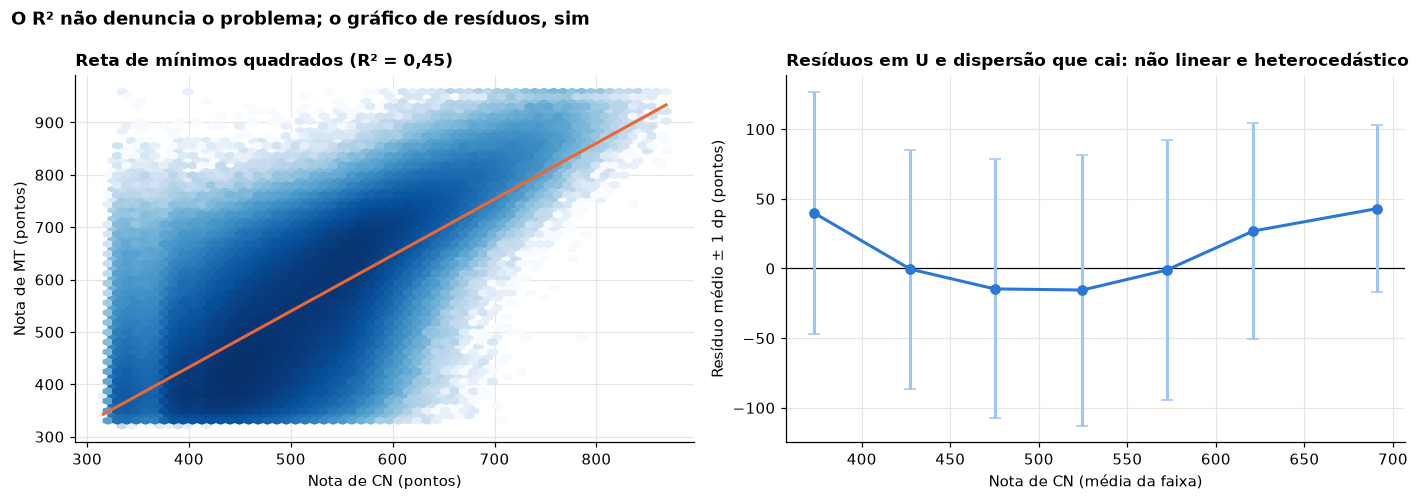

In [63]:
# Resíduos por faixa de CN: se a reta servisse, o resíduo médio ficaria perto de zero em todas as faixas
faixas_cn = pd.cut(cn, [0, 400, 450, 500, 550, 600, 650, 1000])
diag = pd.Series(modelo_cn.resid).groupby(faixas_cn, observed=True).agg(['count', 'mean', 'std'])
display(diag.rename(columns={'count': 'n', 'mean': 'resíduo médio', 'std': 'dp do resíduo'}).round(1))

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.6))
eixos[0].hexbin(cn, mt, gridsize=60, cmap='Blues', bins='log', mincnt=1)   # hexágonos: cor = quantas pessoas naquele ponto
xs = np.array([cn.min(), cn.max()])
eixos[0].plot(xs, a + b * xs, color=LARANJA, lw=2)
eixos[0].set_xlabel('Nota de CN (pontos)'); eixos[0].set_ylabel('Nota de MT (pontos)')
eixos[0].set_title(f'Reta de mínimos quadrados (R² = {br(modelo_cn.rsquared, 2)})', fontsize=11)
centros = pd.Series(cn).groupby(faixas_cn, observed=True).mean()
eixos[1].axhline(0, color='black', lw=0.8)
eixos[1].errorbar(centros, diag['mean'], yerr=diag['std'], fmt='o-', color=AZUL, ecolor='#9ec5f4', capsize=4, lw=2)
eixos[1].set_xlabel('Nota de CN (média da faixa)'); eixos[1].set_ylabel('Resíduo médio ± 1 dp (pontos)')
eixos[1].set_title('Resíduos em U e dispersão que cai: não linear e heterocedástico', fontsize=11)
fig.suptitle('O R² não denuncia o problema; o gráfico de resíduos, sim', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()

**Leitura:** a reta resume bem a tendência (MT sobe cerca de 1 ponto por ponto de CN), mas prevê a **média**, não o aluno: o erro típico é de ±92 pontos. Os resíduos em U mostram que a relação não é bem linear, e a dispersão que cai (heterocedasticidade) mostra que a precisão muda ao longo da escala. O R² não avisa nada disso.

## 8.3 Mesmos resumos, gráficos diferentes: o quarteto de Anscombe

Quatro conjuntos de dados construídos por Anscombe (1973, *The American Statistician* 27(1):17–21) com a mesma média, a mesma variância, o mesmo r e a mesma reta (slide 118).

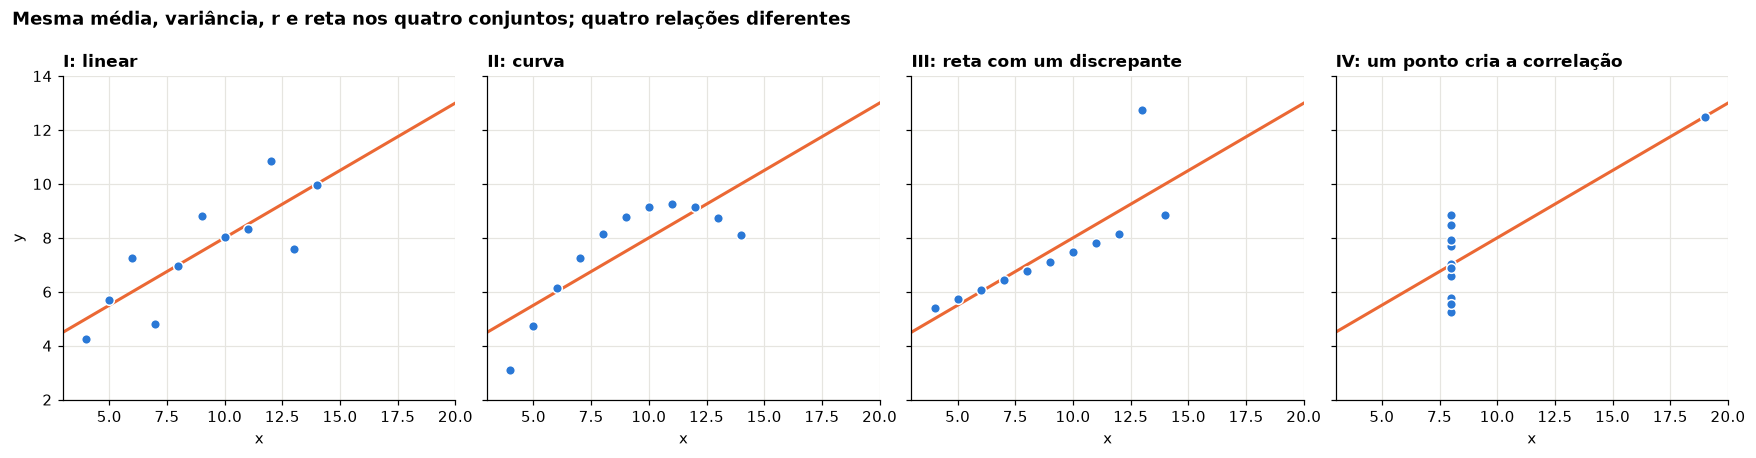

,média x,média y,variância y,r,intercepto,inclinação
I: linear,9.0,7.501,4.127,0.816,3.000,0.5
II: curva,9.0,7.501,4.128,0.816,3.001,0.5
III: reta com um discrepante,9.0,7.500,4.123,0.816,3.002,0.5
IV: um ponto cria a correlação,9.0,7.501,4.123,0.817,3.002,0.5


In [64]:
X_ANS = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
ANSCOMBE = {
    'I: linear':                      (X_ANS, [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]),
    'II: curva':                      (X_ANS, [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]),
    'III: reta com um discrepante':   (X_ANS, [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]),
    'IV: um ponto cria a correlação': ([8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8], [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]),
}
resumos = {}
fig, eixos = plt.subplots(1, 4, figsize=(16, 4.2), sharex=True, sharey=True)
for ax, (nome, (x, y)) in zip(eixos, ANSCOMBE.items()):
    x, y = np.array(x, dtype=float), np.array(y)
    inclinacao, intercepto = np.polyfit(x, y, 1)                      # a reta de mínimos quadrados
    resumos[nome] = {'média x': x.mean(), 'média y': y.mean(), 'variância y': y.var(ddof=1), 'r': np.corrcoef(x, y)[0, 1],
                     'intercepto': intercepto, 'inclinação': inclinacao}
    ax.plot([3, 20], [intercepto + inclinacao * 3, intercepto + inclinacao * 20], color=LARANJA, lw=2)
    ax.scatter(x, y, s=40, color=AZUL, edgecolor='white', zorder=3)
    ax.set_title(nome, fontsize=11); ax.set_xlabel('x')
eixos[0].set_ylabel('y'); eixos[0].set_xlim(3, 20); eixos[0].set_ylim(2, 14)
fig.suptitle('Mesma média, variância, r e reta nos quatro conjuntos; quatro relações diferentes', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()
plt.show()
pd.DataFrame(resumos).T.round(3)

## 8.4 Regressão múltipla: o que permanece

A pergunta P6: quanto de cada fator (renda, escola, sexo, cor/raça) **permanece** quando os outros entram no modelo? Na regressão múltipla, cada coeficiente é a diferença na média de MT associada àquele fator **comparando pessoas iguais nos demais fatores do modelo**. Isso controla o confundimento **observado**; o que não foi medido continua lá.

### Prompt para a IA — a regressão múltipla

O prompt que levaria ao código desta seção. Ele segue o molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**; pede código (não números), dá o contexto e as restrições, e pede as premissas.

```text
Papel: Você é um estatístico revisando uma análise para gestores públicos.

Contexto: DataFrame conc com os concluintes de 2023 que informaram escola (base de análise do ENEM 2023, cerca de 1 milhão). Colunas: NU_NOTA_MT; Q006 (renda, 17 faixas ordinais A–Q); TP_ESCOLA (2 pública, 3 privada); TP_SEXO (M, F); TP_COR_RACA (0 não declarada, 1 branca, 2 preta, 3 parda, 4 amarela, 5 indígena). Dados observacionais.

Pergunta: Quanto da variação de MT está associada à renda, ao tipo de escola, ao sexo e à cor/raça, cada uma mantidas as outras constantes?

Tarefa: (1) Proponha a codificação: renda como código 1–17 (diga o que isso supõe); escola, sexo e cor/raça como indicadoras 0/1, com "branca" como referência. (2) Ajuste com statsmodels (OLS) cinco modelos: só cor/raça; só renda; + escola; + sexo; + cor/raça. (3) Tabela com coeficientes, IC95% e R² de cada modelo. (4) Diagnóstico: resíduos × ajustados e VIF.

Restrições: Não use "efeito" nem "causa". Diga que variáveis importantes ficaram de fora. Só código, sem números.

Formato: Modelos lado a lado; diagnóstico; quatro frases de interpretação em linguagem de associação.
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- n = nº de concluintes de 2023 com TP_ESCOLA 2 ou 3 na base de análise (1.002.841).
- O coeficiente da renda cai quando a escola entra (renda e escola andam juntas).
- Cor/raça como indicadoras 0/1, nunca como número 0–6.
- VIF abaixo de 10 (seção 8.5).
- Texto: "diferença que permanece", não "efeito da cor".

*Slides v11: 124–125.*

**Como as variáveis entram no modelo.** A regressão só trabalha com números. A renda entra como o código da faixa (1 a 17), o que supõe que cada passo de faixa vale o mesmo. As categorias viram **indicadoras** (0 ou 1): `privada` = 1 para escola privada e 0 para pública; `mulher` = 1 para mulheres; uma indicadora para cada grupo de cor/raça, com **Branca** (o maior grupo) como referência. Assim, o coeficiente de `preta` é a diferença entre pretos e brancos, mantidos os outros fatores.

A população é a de quem informou a escola (concluintes de 2023), porque a escola está no modelo.

In [65]:
conc = base[base.TP_ESCOLA.isin([2, 3])].copy()                       # concluintes de 2023 que informaram escola
conc['privada'] = (conc.TP_ESCOLA == 3).astype(int)                   # 1 = privada, 0 = pública
conc['mulher'] = (conc.TP_SEXO == 'F').astype(int)                    # 1 = mulher, 0 = homem
conc['preta'] = (conc.TP_COR_RACA == 2).astype(int)                   # cor/raça: referência = branca
conc['parda'] = (conc.TP_COR_RACA == 3).astype(int)
conc['indígena'] = (conc.TP_COR_RACA == 5).astype(int)
conc['amarela ou não decl.'] = conc.TP_COR_RACA.isin([0, 4]).astype(int)
COR = ['preta', 'parda', 'indígena', 'amarela ou não decl.']
print('n =', br(len(conc), 0))
conc[['NU_NOTA_MT', 'renda', 'privada', 'mulher'] + COR].head()

n = 1.002.841


,NU_NOTA_MT,renda,privada,mulher,preta,parda,indígena,amarela ou não decl.
3,466.7,3,0,1,0,1,0,0
4,338.3,2,0,1,0,1,0,0
11,691.9,4,0,0,0,1,0,0
16,437.0,2,0,1,0,0,0,0
41,628.1,4,0,0,0,0,0,0


Os modelos entram em etapas, como no slide 124: a cada etapa, um fator a mais. Comparar os coeficientes de uma linha para a outra mostra o que muda quando um fator novo é controlado.

In [66]:
etapas = {
    'só cor/raça': COR,
    'só renda': ['renda'],
    'renda + escola': ['renda', 'privada'],
    'renda + escola + sexo': ['renda', 'privada', 'mulher'],
    'renda + escola + sexo + cor/raça': ['renda', 'privada', 'mulher'] + COR,
}
modelos, linhas = {}, []
for nome, variaveis in etapas.items():
    modelos[nome] = sm.OLS(conc.NU_NOTA_MT, sm.add_constant(conc[variaveis])).fit()     # ajusta o modelo
    linhas.append({'modelo': nome, **modelos[nome].params.drop('const').to_dict(), 'R²': modelos[nome].rsquared})
pd.DataFrame(linhas).set_index('modelo')[['renda', 'privada', 'mulher'] + COR + ['R²']].round(3)

,renda,privada,mulher,preta,parda,indígena,amarela ou não decl.,R²
modelo,,,,,,,,
só cor/raça,NaN,NaN,NaN,-73.352,-61.847,-103.185,-37.176,0.068
só renda,15.688,NaN,NaN,NaN,NaN,NaN,NaN,0.228
renda + escola,11.881,60.585,NaN,NaN,NaN,NaN,NaN,0.256
renda + escola + sexo,11.408,60.729,-34.041,NaN,NaN,NaN,NaN,0.275
renda + escola + sexo + cor/raça,10.395,57.850,-34.912,-35.056,-25.670,-56.247,-16.909,0.286


In [67]:
# Intervalos de confiança de 95% dos coeficientes do modelo completo
completo = modelos['renda + escola + sexo + cor/raça']
ic_coef = completo.conf_int()                                         # duas colunas: limite inferior e superior
pd.DataFrame({'coeficiente': completo.params, 'IC95% inf': ic_coef[0], 'IC95% sup': ic_coef[1]}).round(2)

,coeficiente,IC95% inf,IC95% sup
const,509.67,509.12,510.22
renda,10.39,10.33,10.46
privada,57.85,57.25,58.45
mulher,-34.91,-35.33,-34.50
preta,-35.06,-35.76,-34.35
parda,-25.67,-26.13,-25.21
indígena,-56.25,-59.11,-53.38
amarela ou não decl.,-16.91,-18.21,-15.61


**Leitura:**
- Ao incluir a escola, o coeficiente da renda **cai**: parte da associação atribuída à renda era associação com a escola privada (renda e escola andam juntas: o **confundidor**).
- A diferença entre pretos e brancos cai de −73 para −35 pontos com renda, escola e sexo no modelo: parte acompanha esses fatores e parte **permanece**. Não é "efeito da cor": é a diferença que essas variáveis não explicam.
- O R² fica abaixo de 0,3: a maior parte da variação de MT está **entre pessoas parecidas** nesses fatores.

**E o território?** O fio condutor inclui o território, que não está no modelo dos slides. Acrescentando a região do local de prova (indicadoras, com o Sudeste como referência):

In [68]:
REG = ['Norte', 'Nordeste', 'Centro-Oeste', 'Sul']                    # referência: Sudeste
for r in REG:
    conc[r] = (conc.regiao == r).astype(int)
com_regiao = sm.OLS(conc.NU_NOTA_MT, sm.add_constant(conc[['renda', 'privada', 'mulher'] + COR + REG])).fit()
ic_reg = com_regiao.conf_int()
display(pd.DataFrame({'sem região': completo.params, 'com região': com_regiao.params,
                      'IC95% inf (com região)': ic_reg[0], 'IC95% sup (com região)': ic_reg[1]}).loc[com_regiao.params.index].round(2))
print(f'R²: sem região = {br(completo.rsquared, 3)} | com região = {br(com_regiao.rsquared, 3)}')

,sem região,com região,IC95% inf (com região),IC95% sup (com região)
const,509.67,521.29,520.66,521.91
renda,10.39,10.01,9.94,10.08
privada,57.85,57.38,56.78,57.98
mulher,-34.91,-35.32,-35.73,-34.90
preta,-35.06,-33.13,-33.84,-32.42
parda,-25.67,-21.24,-21.72,-20.76
indígena,-56.25,-49.24,-52.10,-46.38
amarela ou não decl.,-16.91,-13.46,-14.76,-12.16
Norte,NaN,-34.95,-35.71,-34.19
Nordeste,NaN,-15.41,-15.93,-14.89


R²: sem região = 0,286 | com região = 0,293


Com a região no modelo, os coeficientes de renda, escola e sexo quase não mudam; as diferenças por cor/raça diminuem um pouco (parte delas acompanha o território), e o R² muda pouco. Comparando pessoas iguais nos demais fatores, participantes do Norte têm média de MT cerca de 35 pontos abaixo das do Sudeste.

## 8.5 Diagnóstico do modelo

Indicadoras só com 0 e 1: True


,VIF
renda,1.57
privada,1.49
mulher,1.01
preta,1.16
parda,1.24
indígena,1.01
amarela ou não decl.,1.03


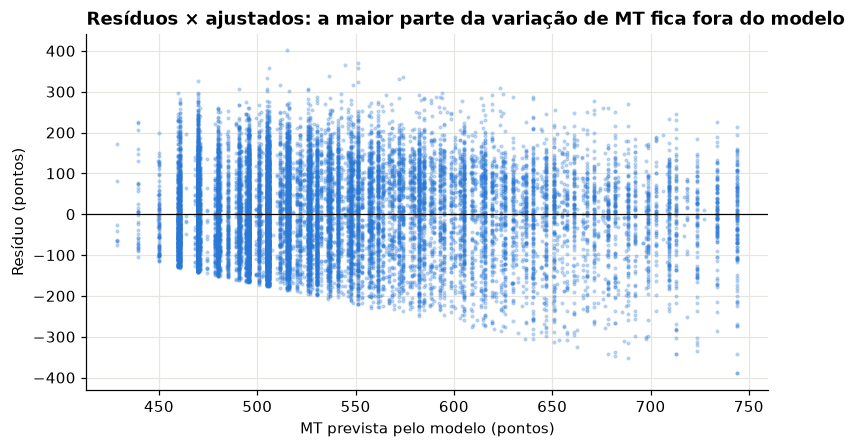

In [69]:
# (a) Codificação: as indicadoras só têm 0 e 1?
print('Indicadoras só com 0 e 1:', bool(conc[['privada', 'mulher'] + COR].isin([0, 1]).all().all()))

# (b) Colinearidade: o VIF mede o quanto cada variável é "explicada" pelas outras; acima de 10 indica problema
X = sm.add_constant(conc[['renda', 'privada', 'mulher'] + COR]).to_numpy(dtype=float)
vif = pd.Series([variance_inflation_factor(X, i) for i in range(1, X.shape[1])], index=['renda', 'privada', 'mulher'] + COR)
display(vif.round(2).to_frame('VIF'))

# (c) Resíduos × valores ajustados, numa amostra de 20 mil pontos (com 1 milhão, o gráfico vira uma mancha)
rng = np.random.default_rng(SEMENTE)                                  # gerador desta seção
i = rng.choice(len(conc), 20_000, replace=False)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(completo.fittedvalues.iloc[i], completo.resid.iloc[i], s=3, alpha=0.25, color=AZUL)
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('MT prevista pelo modelo (pontos)'); ax.set_ylabel('Resíduo (pontos)')
ax.set_title('Resíduos × ajustados: a maior parte da variação de MT fica fora do modelo')
plt.show()

**Leitura em linguagem de gestor:** comparando concluintes de 2023 com a **mesma** faixa de renda, o mesmo sexo e a mesma cor/raça, os de escola privada têm, em média, cerca de 58 pontos a mais em MT, menos da metade da diferença bruta (122), porque parte dela acompanhava a renda. "Controlar" só alcança o que foi medido: qualidade da escola, apoio familiar e trajetória escolar não estão no modelo. Nada disso é causal: são associações numa base observacional, com a seleção de quem comparece (seção 6.7).

---
# Etapa 9 — O relatório

O relatório é texto para a diretoria. Os números vêm das saídas das seções citadas entre parênteses; nenhum é calculado de cabeça. Ele pode ser redigido com ajuda da IA, desde que ela trabalhe **só** com as saídas do notebook:

### Prompt para a IA — o relatório a partir do notebook

O prompt que levaria ao código desta seção, no molde do curso: **Papel, Contexto, Pergunta, Tarefa, Restrições, Formato**.

```text
Papel: Você é um analista que redige relatórios curtos e rigorosos para a diretoria de uma instituição pública.

Contexto: Analisei os microdados do ENEM 2023 num notebook Python. Colo abaixo, para cada seção, o título e as saídas (tabelas e linhas impressas), sem os dados individuais. [colar as saídas das seções 3, 4.3, 4.5, 4.7, 4.8, 4.9, 4.10, 6.7, 7.1, 7.2, 7.4 e 8.4] A pergunta da diretoria era: quanto o desempenho varia com renda, tipo de escola, território, sexo e cor/raça, essas diferenças importam, e quem fica fora da medição?

Pergunta: Quais são os achados principais, com que segurança, e com que limitações?

Tarefa: (1) Escreva um sumário executivo com um item por dimensão (presença, renda, escola, dependência administrativa, território, sexo, cor/raça, modelo conjunto). (2) Em cada item, dê a estimativa, o intervalo de confiança ou o tamanho do efeito, a população analisada e a seção de onde saiu o número. (3) Liste as limitações. (4) Liste as afirmações que dependem de hipótese não verificada.

Restrições: Use SOMENTE os números das saídas coladas; não calcule nem arredonde de outro jeito; se faltar um número, escreva [FALTA] em vez de estimar. Linguagem de associação: nada de "efeito", "causa", "impacto" ou "prova". Não use "significativo" sem o tamanho do efeito.

Formato: Markdown, no máximo uma página, frases curtas, sem jargão; ao final, uma tabela "número citado → seção de origem".
```

**Verificação independente** (o que o analista confere depois de rodar o código que a IA escreveu):
- Conferir cada número do texto na saída da seção citada (a tabela "número → seção" serve para isso).
- Procurar números que não estavam nas saídas coladas: são invenção e saem do texto.
- Procurar palavras causais ("efeito", "impacto", "causa", "leva a") e trocá-las por linguagem de associação.
- Verificar se toda comparação de escola diz "concluintes de 2023" e se a seleção de quem comparece aparece nas limitações.

*Slides v11: 105, 127.*

## 9.1 Relatório: desempenho no ENEM 2023 por renda, escola, território, sexo e cor/raça

**Fonte:** INEP, microdados do ENEM 2023. **Base de análise:** 2.569.190 participantes (65,3% dos 3.933.955 inscritos): presentes nas quatro provas objetivas, redação sem problemas e nenhuma prova objetiva em branco (Etapa 3). Todas as afirmações são de **associação** em dados observacionais.

**Sumário executivo**

1. **Quem fica fora.** A presença na prova de Matemática vai de 58,5% dos inscritos sem renda familiar (faixa A) a 82,2% na faixa mais alta (Q); entre brancos é 73,6%, entre pretos 62,5% e entre indígenas 58,8%; entre os sexos é igual (68,5% e 68,4%). A associação presença × renda está acima do mínimo relevante (V = 0,155). As médias abaixo descrevem quem fez a prova inteira (6.7).
2. **Renda** é a dimensão mais associada à nota: acompanha 23,1% da variação de MT (η²); da faixa A à Q, a média de MT sobe 230 pontos (4.3, 4.10).
3. **Escola.** Numa amostra planejada de 394 concluintes de 2023 por grupo, as privadas têm 134,8 pontos a mais em MT que as públicas (IC95% de 118,4 a 151,2; d = 1,15): diferença relevante, com o intervalo inteiro acima da margem de 23,1 pontos. Na base inteira, a diferença é de 121,8 pontos; dentro de cada faixa de renda, fica entre 62 e 77 pontos; com renda, sexo e cor/raça no modelo, 57,9 pontos (7.2, 4.9, 8.4).
4. **Dependência administrativa.** Federais e privadas ficam acima de estaduais e municipais (4 dos 6 pares com diferença relevante, numa amostra de 608 por grupo); estadual × municipal é inconclusivo. A dependência acompanha 21% da variação de MT entre quem a informou, subconjunto não aleatório dos concluintes (7.4).
5. **Território.** Entre as UFs, a média de MT varia 89 pontos, mas a UF acompanha só 5,8% da variação. Com renda, escola, sexo e cor/raça no modelo, participantes do Norte ficam cerca de 35 pontos abaixo dos do Sudeste (4.5, 4.10, 8.4).
6. **Sexo.** Homens têm média maior em Matemática (+46,5 pontos; d = 0,38) e mulheres na Redação (+36,4; d = 0,21): a direção depende da prova (4.7, 7.1).
7. **Cor/raça.** Brancos têm 77,6 pontos a mais que pretos em MT (d = 0,63). Dentro das faixas de renda, a diferença fica entre 34 e 58 pontos; com renda, escola e sexo no modelo, 35,1 pontos (IC95% de 34,4 a 35,8). Parte da diferença acompanha esses fatores; parte permanece (4.8, 4.9, 8.4).
8. **O conjunto.** O modelo com renda, escola, sexo e cor/raça acompanha 28,6% da variação de MT: a maior parte da variação está entre pessoas parecidas nesses fatores (8.4).

**Limitações**
1. **Seleção:** só quem fez a prova inteira está na base, e a presença varia com renda e cor/raça; é provável, mas não verificável, que as diferenças entre inscritos sejam maiores.
2. **Escola** só para concluintes de 2023; a dependência administrativa falta mais para escolas públicas.
3. **Questionário autodeclarado** (renda, escolaridade do pai, cor/raça); renda em faixas, não em reais.
4. **Território** = local de prova, não residência nem escola.
5. **Observacional:** controlar fatores medidos não remove o confundimento pelo que não foi medido (qualidade da escola, apoio familiar, trajetória escolar).
6. **Privacidade:** nenhum recorte por município × cor/raça × escola, para não reidentificar pessoas.

## 9.2 Checklist do relatório (slide 105)

- [x] Pergunta, hipótese e margem de relevância escritas antes (Etapa 0)
- [x] População analisada e quem ficou de fora (Etapas 2, 3 e 6.7)
- [x] Plano amostral e justificativa do n (Etapas 6 e 7)
- [x] Efeito + IC95% + tamanho do efeito + valor-p, nunca só o valor-p
- [x] Leitura do IC contra a margem de relevância
- [x] Gráficos honestos: título com a conclusão, eixos com unidade, barras a partir de zero, n visível
- [x] Linguagem de associação, nunca de causa
- [ ] Verificação independente de cada número vindo de IA, e registro do uso (abaixo)

## 9.3 Registro de uso de IA (regra 7)

Uma linha por prompt usado na análise. Exemplo de preenchimento:

| Data | Ferramenta/modelo | Etapa | Prompt (resumo) | O que foi aproveitado | Verificação independente | Resultado |
|---|---|---|---|---|---|---|
| dd/mm/aaaa | (nome e versão) | 7.2 | Ex. 1: teste t, n pelo poder, controle negativo | código do sorteio e do teste | t à mão; controle negativo; IC × valor verdadeiro | conferiu |
| | | | | | | |


**A assinatura no relatório é sua, não da IA.**